# Model 11 — Portable Dual-Model Radar Classification

**One notebook. One local `model_11/` folder. Two saved models. One results workbook. A paced live replay, refined dark/light research plots, and optional interactive trajectory animation.**

This edition is designed for a local/offline machine as well as Colab **when the required Python packages and the `model_11/` folder are available**.

- First run with no compatible artifacts: generates synthetic training tracks, trains the CNN–BiGRU–attention model and ExtraTrees, evaluates on track-disjoint synthetic splits, then saves the complete model bundle into `./model_11/`.
- Later runs in the same local project folder: loads both models and their exact preprocessing/schema from `./model_11/`; it **does not retrain** unless you explicitly set `FORCE_RETRAIN = True`.
- Real data: uses only the input measurements for inference; class/label columns in the CSV are ignored. Both CNN and ExtraTrees replay packet by packet, with a 30-packet warm-up for ExtraTrees.
- Outputs: one formatted Excel workbook and separate research figures under `./model_11/outputs/`. Plotly enables interactive, offline-exportable charts and trajectory animation; Matplotlib remains the fallback.
- No Google Drive mounting, no cloud dependency, no automatic axis swap, and no collection of diagnostic CSVs.

**Portable-folder rule:** keep this notebook and the entire `model_11/` folder together. A local/offline Jupyter run reuses the same folder on disk. Colab's `/content` is temporary; after a fresh Colab runtime, you must upload/copy the saved `model_11/` files again or the models will be trained again. This notebook intentionally does not hide that platform limitation.

**Research caveat:** all reported validation/IID/stress results are synthetic-only. Real-track labels are unavailable, model scores are uncalibrated, and outputs are provisional candidates—not confirmed target identities.

**Saved preprocessing is included:** `preprocessing.joblib` stores the CNN imputer, `RobustScaler`, and label encoder. ExtraTrees is saved as a fitted scikit-learn pipeline that includes its own imputer. Keep the complete `model_11/` folder; do not keep only `cnn_model.keras`.


In [1]:
!pip install tensorflow
!pip install openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 17.2 MB/s  0:00:17
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 71.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [openpyxl]


In [2]:
# Offline-friendly dependency check: deliberately does not run pip or require internet.
import importlib.util, sys
REQUIRED_MODULES = {
    "numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
    "sklearn": "scikit-learn", "tensorflow": "tensorflow", "joblib": "joblib",
    "openpyxl": "openpyxl",
}
missing = [package for module, package in REQUIRED_MODULES.items()
           if importlib.util.find_spec(module) is None]
if missing:
    raise ModuleNotFoundError(
        "Required packages are missing: " + ", ".join(missing) + "\n"
        "This notebook does not install packages automatically so it can run offline. "
        "Install these packages in the environment before running, or use an environment "
        "prepared with the matching TensorFlow/scikit-learn versions."
    )
print("✅ Core dependencies are present. No network installation attempted.")
print("ℹ️ Plotly is optional: if present, the notebook writes an interactive offline HTML dashboard; otherwise it creates a static PNG dashboard.")

✅ Core dependencies are present. No network installation attempted.
ℹ️ Plotly is optional: if present, the notebook writes an interactive offline HTML dashboard; otherwise it creates a static PNG dashboard.


In [3]:
import os, json, random, warnings, joblib
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sklearn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay, f1_score, balanced_accuracy_score
from tensorflow.keras.layers import (Input, Conv1D, Dense, Dropout, BatchNormalization,
    LayerNormalization, MultiHeadAttention, Bidirectional, GRU, concatenate,
    GlobalAveragePooling1D, GlobalMaxPooling1D)
from tensorflow.keras.models import Model

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED); tf.random.set_seed(SEED)

CLASSES = [
    "CIVILIAN_AIRCRAFT", "FIGHTER_AIRCRAFT", "HELICOPTER", "DRONE",
    "SURFACE_MISSILE", "AERIAL_MISSILE", "SKIFF", "BOAT", "SHIP"
]

# Local, portable artifact storage. Launch Jupyter from the project directory so this is beside the notebook.
PROJECT_DIR = Path.cwd().resolve()
ARTIFACT_DIR = PROJECT_DIR / "model_11"
OUTPUT_DIR = ARTIFACT_DIR / "outputs"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BUNDLE_VERSION = "radar-model11-portable-v2"
FORCE_RETRAIN = False  # change to True only to intentionally rebuild/overwrite the local saved models
RUNNING_IN_COLAB = False
try:
    import google.colab  # type: ignore
    RUNNING_IN_COLAB = True
except Exception:
    pass

BUNDLE_FILES = [
    "cnn_model.keras", "preprocessing.joblib", "extratrees_model.joblib",
    "bundle_metadata.json", "evaluation_reports.joblib"
]
BUNDLE_COMPLETE = all((ARTIFACT_DIR / name).exists() for name in BUNDLE_FILES)
BUNDLE_VERSION_OK = False
if BUNDLE_COMPLETE:
    try:
        _meta_check = json.loads((ARTIFACT_DIR / "bundle_metadata.json").read_text())
        BUNDLE_VERSION_OK = _meta_check.get("bundle_version") == BUNDLE_VERSION
    except Exception:
        BUNDLE_VERSION_OK = False
if BUNDLE_COMPLETE and not BUNDLE_VERSION_OK and not FORCE_RETRAIN:
    raise RuntimeError(
        f"A model bundle exists in {ARTIFACT_DIR}, but its version is incompatible with this notebook. "
        "To preserve it, back up the folder first. Then either use the notebook version that created it, "
        "or deliberately set FORCE_RETRAIN=True to rebuild the bundle."
    )
LOAD_SAVED_MODELS = bool(BUNDLE_COMPLETE and BUNDLE_VERSION_OK and not FORCE_RETRAIN)

SAMPLE_SECONDS = 10.0
SEQUENCE_LENGTH = 30
TRACK_SUMMARY_STATS = ("median", "q10", "q90", "std", "delta")
TRACKS_PER_CLASS = 32  # per class in EACH training scenario family; +33% training tracks vs Model 19
TRAIN_WINDOW_STRIDE = 3
POST_BREAKOUT_CONTEXT = 8
BATCH_SIZE = 128
MAX_EPOCHS = 30  # early stopping prevents wasting epochs after validation stops improving

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
# Confirmed operating assumptions supplied by the user:
# - radar is the coordinate origin; pos_z is relative to the radar
# - position, velocity and acceleration are intended to share one coordinate frame
# - ntp_sec is in seconds; time differences are computed in seconds
# The 3-storey mounting offset is intentionally not corrected in this version,
# following the team's guidance that it is negligible for this project.
# A cross-axis derivative pattern is logged as a diagnostic only; never auto-swap axes.
CONFIRM_VELOCITY_ACCEL_XY_SWAP = False

# Packet replay: append-only text, with plots only after the complete replay.
PLAYBACK_DELAY = 0.12        # seconds per packet; set 0.0 for instant replay or 0.20 for slower presentation
PRINT_EVERY_N_PACKETS = 1    # 1 = every timestamp, like Model 11

print("Target classes:", len(CLASSES))
print("Integrated pipeline: CNN packet replay + rolling ExtraTrees replay; real labels are never used.")
print("Project directory:", PROJECT_DIR)
print("Local model/artifact directory:", ARTIFACT_DIR)
print("Results directory:", OUTPUT_DIR)
print("Mode:", "LOAD SAVED MODELS (no training)" if LOAD_SAVED_MODELS else "TRAIN MODE (first setup or FORCE_RETRAIN=True)")
if RUNNING_IN_COLAB:
    print("⚠️ Colab runtime storage is temporary. Download/copy the model_11 folder before the runtime resets if you need to reuse it.")
else:
    print("✅ Local persistence: artifacts remain in this model_11 folder between runs on this machine.")

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow: 2.21.0
GPU available: False
Target classes: 9
Integrated pipeline: CNN packet replay + rolling ExtraTrees replay; real labels are never used.
Project directory: /content
Local model/artifact directory: /content/model_11
Results directory: /content/model_11/outputs
Mode: TRAIN MODE (first setup or FORCE_RETRAIN=True)
⚠️ Colab runtime storage is temporary. Download/copy the model_11 folder before the runtime resets if you need to reuse it.


## 1. Shared feature extraction

In [4]:
FEATURE_COLS = [
    "pos_z", "vel_mag", "vel_xy_mag", "range_mag", "accel_mag", "jerk_mag",
    "jerk_to_accel_ratio", "curvature_3d", "specific_energy", "energy_rate",
    "z_ratio", "vertical_accel_ratio", "accel_mag_roll_mean", "accel_mag_roll_std",
    "jerk_mag_roll_mean", "jerk_mag_roll_std", "energy_rate_roll_mean",
    "energy_rate_roll_std", "cum_max_accel", "cum_max_jerk", "cum_max_energy_rate"
]
UNCERTAINTY_COLS = [
    "std_dev_x", "std_dev_y", "std_dev_z", "std_dev_vx", "std_dev_vy", "std_dev_vz",
    "std_dev_ax", "std_dev_ay", "std_dev_az", "cov_x_vx", "cov_y_vy", "cov_z_vz"
]
METADATA_NOT_FEATURES = {
    "track_no", "ntp_sec", "track_class", "track_type", "track_category_val",
    "hostility", "is_simulated", "source", "destination", "packet_size", "packet_type",
    "packet_category", "radar_id", "track_state", "manoeuvre_state", "assoc_indication"
}

def _numeric_col(df, col):
    if col not in df.columns:
        return pd.Series(np.nan, index=df.index, dtype=float)
    return pd.to_numeric(df[col], errors="coerce").astype(float)

def robust_feature_extractor(data):
    """Shared causal extractor for simulator and ICD input; never reads class metadata. Per-track rolling/cumulative values use current and prior packets only."""
    df = data.copy()
    if "track_no" not in df.columns:
        df["track_no"] = 1
    if "ntp_sec" not in df.columns:
        df["ntp_sec"] = np.arange(len(df), dtype=float) * SAMPLE_SECONDS
    df["ntp_sec"] = _numeric_col(df, "ntp_sec")
    df["track_no"] = df["track_no"].fillna(1)
    df = df.dropna(subset=["ntp_sec"]).sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

    for c in ["pos_x", "pos_y", "pos_z"]:
        if c not in df.columns:
            raise ValueError(f"Required position column missing: {c}")
        df[c] = _numeric_col(df, c)

    # User-confirmed ntp_sec units are seconds. Use adjacent timestamp differences in seconds;
    # ntp_frac is intentionally not combined in this version.
    dt = df.groupby("track_no")["ntp_sec"].diff()
    fallback_dt = SAMPLE_SECONDS  # fallback only for first/invalid/non-positive intervals
    df["dt"] = dt.where((dt > 0) & np.isfinite(dt), fallback_dt).fillna(fallback_dt).clip(lower=0.01)

    # Preserve valid sensor-provided velocity/acceleration components. Derive only missing cells.
    for a in ["x", "y", "z"]:
        pos = _numeric_col(df, f"pos_{a}")
        derived_v = pos.groupby(df["track_no"]).diff() / df["dt"]
        provided_v = _numeric_col(df, f"vel_{a}")
        df[f"vel_{a}"] = provided_v.where(np.isfinite(provided_v), derived_v)
        df[f"vel_{a}"] = df.groupby("track_no")[f"vel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

        derived_a = df.groupby("track_no")[f"vel_{a}"].diff() / df["dt"]
        provided_a = _numeric_col(df, f"accel_{a}")
        df[f"accel_{a}"] = provided_a.where(np.isfinite(provided_a), derived_a)
        df[f"accel_{a}"] = df.groupby("track_no")[f"accel_{a}"].transform(lambda s: s.ffill()).fillna(0.0)

    v = df[["vel_x", "vel_y", "vel_z"]].to_numpy(float)
    a = df[["accel_x", "accel_y", "accel_z"]].to_numpy(float)
    dt_arr = df["dt"].to_numpy(float)

    # Trust the ICD's magnitude fields when available; these are axis-rotation invariant.
    derived_speed = np.linalg.norm(v, axis=1)
    raw_speed = _numeric_col(df, "vel_mag").to_numpy()
    df["vel_mag"] = np.where(np.isfinite(raw_speed) & (raw_speed >= 0), raw_speed, derived_speed)
    df["vel_xy_mag"] = np.sqrt(df["vel_x"]**2 + df["vel_y"]**2)
    derived_range = np.sqrt(df["pos_x"]**2 + df["pos_y"]**2 + df["pos_z"]**2)
    raw_range = _numeric_col(df, "range_mag").to_numpy()
    df["range_mag"] = np.where(np.isfinite(raw_range) & (raw_range >= 0), raw_range, derived_range)
    derived_accel = np.linalg.norm(a, axis=1)
    raw_accel = _numeric_col(df, "accel_mag").to_numpy()
    df["accel_mag"] = np.where(np.isfinite(raw_accel) & (raw_accel >= 0), raw_accel, derived_accel)

    jerk_components = np.column_stack([
        df.groupby("track_no")[f"accel_{axis}"].diff().to_numpy() / dt_arr
        for axis in ["x", "y", "z"]
    ])
    jerk_components = np.nan_to_num(jerk_components, nan=0.0, posinf=0.0, neginf=0.0)
    df["jerk_mag"] = np.linalg.norm(jerk_components, axis=1)
    df["jerk_to_accel_ratio"] = df["jerk_mag"] / np.maximum(df["accel_mag"].to_numpy(), 0.1)

    cross = np.cross(v, a)
    cross_mag = np.linalg.norm(cross, axis=1)
    df["curvature_3d"] = cross_mag / (df["vel_mag"].to_numpy()**3 + 1e-3)

    # Assumes pos_z is metres and velocity is metres/second. Change this if the ICD says otherwise.
    vz = df["vel_z"].to_numpy()
    az = df["accel_z"].to_numpy()
    df["specific_energy"] = 9.81 * df["pos_z"].to_numpy() + 0.5 * df["vel_mag"].to_numpy()**2
    df["energy_rate"] = 9.81 * vz + np.sum(v * a, axis=1)
    df["z_ratio"] = vz / (df["vel_mag"].to_numpy() + 1e-6)
    df["vertical_accel_ratio"] = az / (df["accel_mag"].to_numpy() + 1e-6)

    for col in ["accel_mag", "jerk_mag", "energy_rate"]:
        grouped = df.groupby("track_no")[col]
        df[f"{col}_roll_mean"] = grouped.transform(lambda s: s.rolling(3, min_periods=1).mean())
        df[f"{col}_roll_std"] = grouped.transform(lambda s: s.rolling(3, min_periods=2).std()).fillna(0.0)
        df[f"cum_max_{col.replace('_mag', '')}"] = grouped.cummax() if col != "energy_rate" else grouped.transform(lambda s: s.abs().cummax())

    # Normalize names to the exact 21-feature contract. Cumulative energy uses absolute magnitude.
    df["cum_max_accel"] = df.groupby("track_no")["accel_mag"].cummax()
    df["cum_max_jerk"] = df.groupby("track_no")["jerk_mag"].cummax()
    df["cum_max_energy_rate"] = df.groupby("track_no")["energy_rate"].transform(lambda s: s.abs().cummax())
    df["jerk_to_accel_ratio"] = np.log1p(np.clip(df["jerk_to_accel_ratio"], 0, 1e4))
    df["curvature_3d"] = np.log1p(np.clip(df["curvature_3d"], 0, 1e4))

    df[FEATURE_COLS] = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
    return df


def coordinate_frame_audit(raw):
    """Diagnostic only: compare velocity components with position derivatives; never auto-remap.

    This pipeline's model features do not use signed horizontal X/Y channels. Therefore this
    check is retained as a data-quality note, not a hard gate on candidate predictions.
    """
    if not all(c in raw.columns for c in ["pos_x", "pos_y", "pos_z", "vel_x", "vel_y", "vel_z", "ntp_sec"]):
        print("Coordinate audit skipped: position/velocity/time fields are incomplete.")
        return pd.DataFrame()
    q = raw.copy().sort_values(["track_no", "ntp_sec"] if "track_no" in raw.columns else ["ntp_sec"])
    if "track_no" in q.columns:
        dt = q.groupby("track_no")["ntp_sec"].diff().replace(0, np.nan)
    else:
        dt = q["ntp_sec"].diff().replace(0, np.nan)
    rows = []
    for vaxis in ["x", "y", "z"]:
        v = pd.to_numeric(q[f"vel_{vaxis}"], errors="coerce")
        corrs = {}
        for paxis in ["x", "y", "z"]:
            pos_series = pd.to_numeric(q[f"pos_{paxis}"], errors="coerce")
            derived = (pos_series.groupby(q["track_no"]).diff() if "track_no" in q.columns else pos_series.diff()) / dt
            corrs[paxis] = v.corr(derived)
        rows.append({"reported_velocity_axis": vaxis, **{f"corr_with_dpos_{k}": val for k, val in corrs.items()}})
    out = pd.DataFrame(rows)
    print("Position/velocity axis audit (diagnostic only; no automatic axis swapping):")
    display(out.round(3))
    for vaxis, paxes in [("x", ["x", "y"]), ("y", ["y", "x"])]:
        row = out[out["reported_velocity_axis"] == vaxis].iloc[0]
        same, other = row[f"corr_with_dpos_{paxes[0]}"], row[f"corr_with_dpos_{paxes[1]}"]
        if pd.notna(other) and (pd.isna(same) or other > same + 0.25):
            print(f"ℹ️ Cross-axis pattern: vel_{vaxis} aligns more with d(pos_{paxes[1]}) than d(pos_{paxes[0]}). No coordinates are changed; this is recorded as a diagnostic because signed horizontal X/Y features are not used by this classifier.")
    return out

print("Model-11-style kinematic features:", len(FEATURE_COLS))
print("Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)")

Model-11-style kinematic features: 21
Uncertainty/covariance inputs used by classifier: 0 (diagnostics only)


## 2. Synthetic track generation

In [5]:
# Synthetic classes have overlapping envelopes by design. Ranges are illustrative priors,
# not authoritative performance envelopes for real platforms.
PROFILES = {
    "CIVILIAN_AIRCRAFT": dict(speed=(180, 310), altitude=(4500, 14000), vz=(-5, 5), turn=(0.0004, 0.006), sea=False),
    "FIGHTER_AIRCRAFT":   dict(speed=(220, 900), altitude=(200, 19000), vz=(-22, 22), turn=(0.001, 0.028), sea=False),
    "HELICOPTER":         dict(speed=(15, 115), altitude=(10, 4500), vz=(-7, 7), turn=(0.008, 0.055), sea=False),
    "DRONE":              dict(speed=(5, 230), altitude=(10, 13000), vz=(-12, 12), turn=(0.004, 0.050), sea=False),
    "SURFACE_MISSILE":    dict(speed=(260, 1250), altitude=(5, 100), vz=(-16, 16), turn=(0.001, 0.025), sea=False),
    "AERIAL_MISSILE":     dict(speed=(350, 1600), altitude=(500, 26000), vz=(-40, 40), turn=(0.002, 0.035), sea=False),
    "SKIFF":              dict(speed=(1, 22), altitude=(1, 4), vz=(0, 0), turn=(0.001, 0.025), sea=True),
    "BOAT":               dict(speed=(2, 28), altitude=(2, 10), vz=(0, 0), turn=(0.0005, 0.016), sea=True),
    "SHIP":               dict(speed=(1, 18), altitude=(5, 28), vz=(0, 0), turn=(0.0002, 0.008), sea=True),
}

# The three training families vary sensor quality and manoeuvres. Validation and test are
# whole held-out scenario families, not random windows from the training distribution.
SCENARIO_SETTINGS = {
    "nominal_train":       dict(sensor_mult=0.85, dropout=0.00, outlier=0.000, maneuver_p=0.20, sea_state="calm"),
    "moderate_noise_train":dict(sensor_mult=1.25, dropout=0.015, outlier=0.004, maneuver_p=0.35, sea_state="moderate"),
    "maneuver_mix_train":  dict(sensor_mult=1.05, dropout=0.020, outlier=0.006, maneuver_p=0.65, sea_state="moderate"),
    "validation_shift":    dict(sensor_mult=1.45, dropout=0.035, outlier=0.010, maneuver_p=0.50, sea_state="rough"),
    # Independent tracks from a familiar regime: no trajectory is reused from training.
    "heldout_iid_test":    dict(sensor_mult=1.15, dropout=0.018, outlier=0.004, maneuver_p=0.38, sea_state="moderate"),
    # Deliberately harder distribution shift; interpret separately from IID generalization.
    "stress_unseen_test":  dict(sensor_mult=1.85, dropout=0.060, outlier=0.018, maneuver_p=0.68, sea_state="rough"),
}
TRAIN_FAMILIES = ["nominal_train", "moderate_noise_train", "maneuver_mix_train"]
VALIDATION_FAMILY = "validation_shift"
IID_TEST_FAMILY = "heldout_iid_test"
STRESS_TEST_FAMILY = "stress_unseen_test"
TEST_FAMILY = STRESS_TEST_FAMILY  # retained for the existing static vessel diagnostic
TRACKS_PER_CLASS_TRAIN_FAMILY = TRACKS_PER_CLASS
TRACKS_PER_CLASS_VALIDATION = 12
TRACKS_PER_CLASS_IID_TEST = 12
TRACKS_PER_CLASS_TEST = 15

# A disguise changes early motion, not the physical identity label. Keep only post-breakout
# contexts as supervised identity windows; early ambiguous prefixes are intentionally excluded.
MIMIC_PROFILES = {
    "FIGHTER_AIRCRAFT": dict(speed=(220, 300), altitude=(6500, 14000), turn=(0.0003, 0.005)),
    "DRONE": dict(speed=(20, 95), altitude=(30, 2800), turn=(0.004, 0.025)),
    "AERIAL_MISSILE": dict(speed=(300, 800), altitude=(1000, 18000), turn=(0.001, 0.012)),
}

SEA_RESPONSE = {
    # Amplitude ranges for the low-frequency motion seen in a track report. Faster wave
    # components are attenuated by typical tracking/filtering and may be under-sampled.
    "calm": (0.12, 0.45),
    "moderate": (0.35, 1.10),
    "rough": (0.80, 2.40),
}
VESSEL_RESPONSE_SCALE = {"SKIFF": 1.0, "BOAT": 1.35, "SHIP": 1.65}


def _smoothstep01(x):
    x = float(np.clip(x, 0.0, 1.0))
    return x*x*(3.0 - 2.0*x)


def generate_complex_trajectory(target_class, track_id, rng, scenario_family, duration=None):
    """Generate a physical trajectory, then an imperfect radar measurement stream.

    `_true_*` columns are simulator diagnostics only. Model features are computed exclusively
    from reported measurement columns. `track_class`/metadata are never model inputs.
    """
    spec = PROFILES[target_class]
    # Copy scenario defaults, then randomize measurement conditions PER TRACK.
    # Sensor randomization is class-independent: the sensor quality must not reveal the label.
    settings = dict(SCENARIO_SETTINGS[scenario_family])
    if scenario_family in TRAIN_FAMILIES:
        settings["sensor_mult"] = float(np.clip(settings["sensor_mult"] * rng.uniform(0.75, 1.30), 0.55, 2.35))
        settings["dropout"] = float(np.clip(settings["dropout"] + rng.uniform(-0.008, 0.018), 0.0, 0.09))
        settings["outlier"] = float(np.clip(settings["outlier"] + rng.uniform(-0.002, 0.006), 0.0, 0.03))
        settings["maneuver_p"] = float(np.clip(settings["maneuver_p"] + rng.uniform(-0.15, 0.15), 0.05, 0.90))
        # Keep scenario-family structure while allowing multiple sea conditions in training.
        if spec["sea"]:
            sea_prob = {
                "nominal_train": [0.70, 0.25, 0.05],
                "moderate_noise_train": [0.20, 0.60, 0.20],
                "maneuver_mix_train": [0.10, 0.50, 0.40],
            }.get(scenario_family, [0.25, 0.50, 0.25])
            settings["sea_state"] = str(rng.choice(["calm", "moderate", "rough"], p=sea_prob))
    n = int(duration if duration is not None else rng.integers(55, 87))
    dt = SAMPLE_SECONDS
    is_sea = bool(spec["sea"])
    sea_state = settings["sea_state"] if is_sea else "not_applicable"

    # Physical height: an aircraft's altitude or a vessel's radar-reflection reference height.
    if target_class == "SURFACE_MISSILE":
        base_z = float(rng.uniform(5, 100) if rng.random() < 0.70 else rng.uniform(500, 7000))
    elif is_sea:
        base_z = float(rng.uniform(*spec["altitude"]))
    else:
        base_z = float(rng.uniform(*spec["altitude"]))

    base_speed = float(rng.uniform(*spec["speed"]))
    heading = float(rng.uniform(-np.pi, np.pi))
    # Log-uniform distance spans nearer and farther targets without clustering every track
    # around one narrow range. This is a simulator prior to be tuned against future labelled data.
    radius0 = float(np.exp(rng.uniform(np.log(8_000.0), np.log(180_000.0))))
    bearing0 = float(rng.uniform(-np.pi, np.pi))
    center_pos = np.array([radius0*np.cos(bearing0), radius0*np.sin(bearing0), 0.0 if is_sea else base_z], dtype=float)

    # Current/wind drift is part of true ground motion, not measurement noise.
    if is_sea:
        current_speed = float(rng.uniform(0.05, 1.2))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    else:
        current_speed = float(rng.uniform(0.0, 2.0))
        current_heading = float(rng.uniform(-np.pi, np.pi))
    current_xy = np.array([current_speed*np.cos(current_heading), current_speed*np.sin(current_heading)])

    is_disguised = bool(target_class in MIMIC_PROFILES and rng.random() < 0.25)
    breakout_step = int(rng.integers(max(14, n//3), max(15, 2*n//3)) if is_disguised else -1)
    mimic = MIMIC_PROFILES.get(target_class, None) if is_disguised else None
    mimic_speed = float(rng.uniform(*mimic["speed"])) if mimic else base_speed
    # Natural smooth speed changes: relative size/period are independent of class identity.
    speed_mod_amp = float(rng.uniform(0.01, 0.08) * base_speed)
    speed_mod_period = float(rng.uniform(18.0, 55.0))
    speed_mod_phase = float(rng.uniform(-np.pi, np.pi))
    if mimic and not is_sea:
        base_z = float(rng.uniform(*mimic["altitude"]))
        center_pos[2] = base_z
    mimic_turn = float(rng.uniform(*mimic["turn"])) if mimic else float(rng.uniform(*spec["turn"]))
    turn_rate = float(rng.uniform(*spec["turn"]))

    # Randomly choose a smooth mid-track manoeuvre. The scenario family controls how often it occurs.
    has_manoeuvre = bool(rng.random() < settings["maneuver_p"])
    event_center = int(rng.integers(16, max(17, n-12))) if has_manoeuvre else -999
    event_width = float(rng.uniform(4, 10)) if has_manoeuvre else 1.0
    event_turn = float(rng.choice([-1, 1]) * rng.uniform(*spec["turn"]) * rng.uniform(0.5, 1.4)) if has_manoeuvre else 0.0
    event_speed_delta = float(rng.uniform(-0.18, 0.22) * base_speed) if has_manoeuvre else 0.0
    event_climb = float(rng.uniform(-0.25, 0.25) * max(abs(spec["vz"][1]), 1.0)) if (has_manoeuvre and not is_sea) else 0.0

    # Low-frequency wave response: heave plus small roll/pitch-driven apparent reflection shifts.
    if is_sea:
        amp_low, amp_high = SEA_RESPONSE[sea_state]
        vessel_scale = VESSEL_RESPONSE_SCALE[target_class]
        heave_amps = rng.uniform(amp_low, amp_high, size=2) * vessel_scale
        periods = rng.uniform(22.0, 58.0, size=2)  # filtered track-level swell, not raw wave period
        phases = rng.uniform(-np.pi, np.pi, size=2)
        sway_amps = rng.uniform(0.15, 0.55, size=2) * vessel_scale * (1.0 if sea_state == "calm" else 1.8)
        sway_periods = rng.uniform(24.0, 64.0, size=2)
        sway_phases = rng.uniform(-np.pi, np.pi, size=2)
    else:
        heave_amps = np.zeros(2); periods = np.array([30.0, 45.0]); phases = np.zeros(2)
        sway_amps = np.zeros(2); sway_periods = np.array([30.0, 45.0]); sway_phases = np.zeros(2)

    # Sensor noise is range/scenario dependent and class-independent. AR(1) bias makes errors
    # temporally correlated; occasional outliers and missed detections model imperfect tracking.
    pos_bias = np.zeros(3); vel_bias = np.zeros(3); acc_bias = np.zeros(3)
    previous_true_v = None
    previous_true_a = None
    rows = []
    jitter = 0.0
    for step in range(n):
        t = step * dt
        if mimic and step < breakout_step:
            blend = 0.0
        elif mimic:
            blend = _smoothstep01((step - breakout_step + 1) / 6.0)
        else:
            blend = 1.0
        desired_speed = mimic_speed*(1-blend) + base_speed*blend
        desired_speed += speed_mod_amp * np.sin(2*np.pi*step/speed_mod_period + speed_mod_phase)
        event_strength = np.exp(-0.5*((step-event_center)/event_width)**2) if has_manoeuvre else 0.0
        target_turn_limit = mimic_turn*(1-blend) + float(np.mean(spec["turn"]))*blend if mimic else float(np.mean(spec["turn"]))
        turn_rate += rng.normal(0, max(target_turn_limit*0.10, 1e-5))
        turn_rate += event_turn * event_strength * dt * 0.025
        turn_rate = float(np.clip(turn_rate, -max(target_turn_limit, 1e-4)*1.8, max(target_turn_limit, 1e-4)*1.8))
        heading += turn_rate * dt
        speed_noise = max(0.015*base_speed, 0.15) * settings["sensor_mult"]
        speed = float(np.clip(desired_speed + rng.normal(0, speed_noise) + event_speed_delta*event_strength,
                              max(0.1, spec["speed"][0]*0.55), spec["speed"][1]*1.10))

        if is_sea:
            true_vz_center = 0.0
            center_velocity = np.array([speed*np.cos(heading)+current_xy[0], speed*np.sin(heading)+current_xy[1], 0.0])
        else:
            vz_limit = max(abs(spec["vz"][1]), 1.0)
            climb = event_climb * event_strength
            true_vz_center = float(np.clip(rng.normal(0, max(vz_limit*0.12, 0.15)) + climb, -vz_limit, vz_limit))
            horiz = np.sqrt(max(speed*speed - true_vz_center*true_vz_center, 0.0))
            center_velocity = np.array([horiz*np.cos(heading)+current_xy[0], horiz*np.sin(heading)+current_xy[1], true_vz_center])

        if step > 0:
            center_pos = center_pos + center_velocity * dt

        if is_sea:
            omega = 2*np.pi/periods
            heave = float(np.sum(heave_amps * np.sin(omega*t + phases)))
            heave_v = float(np.sum(heave_amps * omega * np.cos(omega*t + phases)))
            heave_a = float(-np.sum(heave_amps * omega**2 * np.sin(omega*t + phases)))
            sway_omega = 2*np.pi/sway_periods
            sway_x = float(np.sum(sway_amps * np.sin(sway_omega*t + sway_phases)))
            sway_vx = float(np.sum(sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases)))
            sway_ax = float(-np.sum(sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases)))
            sway_y = float(np.sum(0.65*sway_amps * np.sin(sway_omega*t + sway_phases + 0.9)))
            sway_vy = float(np.sum(0.65*sway_amps * sway_omega * np.cos(sway_omega*t + sway_phases + 0.9)))
            sway_ay = float(-np.sum(0.65*sway_amps * sway_omega**2 * np.sin(sway_omega*t + sway_phases + 0.9)))
            true_pos = np.array([center_pos[0] + sway_x, center_pos[1] + sway_y, base_z + heave])
            true_v = np.array([center_velocity[0] + sway_vx, center_velocity[1] + sway_vy, heave_v])
            wave_a = np.array([sway_ax, sway_ay, heave_a])
        else:
            true_pos = center_pos.copy()
            true_v = center_velocity.copy()
            wave_a = np.zeros(3)
        if previous_true_v is None:
            true_a = wave_a.copy()
        else:
            true_a = (true_v - previous_true_v) / dt
        true_speed = float(np.linalg.norm(true_v))
        true_range = float(np.linalg.norm(true_pos))

        # Noise depends on range and scenario, not on the target class.
        sigma_p = float(np.clip(8.0 + true_range*0.00016, 8.0, 65.0) * settings["sensor_mult"])
        sigma_v = float(np.clip(0.25 + true_range*0.000006, 0.25, 2.2) * settings["sensor_mult"])
        sigma_a = float(np.clip(0.08 + true_speed*0.0020, 0.10, 1.8) * settings["sensor_mult"])
        pos_sigmas = np.array([sigma_p, sigma_p*rng.uniform(0.85, 1.15), sigma_p*rng.uniform(0.80, 1.25)])
        vel_sigmas = np.array([sigma_v, sigma_v*rng.uniform(0.85, 1.20), sigma_v*rng.uniform(0.80, 1.25)])
        acc_sigmas = np.array([sigma_a, sigma_a*rng.uniform(0.80, 1.25), sigma_a*rng.uniform(0.80, 1.25)])
        pos_bias = 0.72*pos_bias + rng.normal(0, pos_sigmas*0.22, 3)
        vel_bias = 0.62*vel_bias + rng.normal(0, vel_sigmas*0.22, 3)
        acc_bias = 0.55*acc_bias + rng.normal(0, acc_sigmas*0.18, 3)
        obs_pos = true_pos + pos_bias + rng.normal(0, pos_sigmas*0.70, 3)
        obs_v = true_v + vel_bias + rng.normal(0, vel_sigmas*0.75, 3)
        obs_a = true_a + acc_bias + rng.normal(0, acc_sigmas*0.80, 3)
        is_outlier = bool(rng.random() < settings["outlier"])
        if is_outlier:
            obs_pos += rng.normal(0, pos_sigmas*6.0, 3)
            obs_v += rng.normal(0, vel_sigmas*3.5, 3)
            obs_a += rng.normal(0, acc_sigmas*3.0, 3)

        # Ensure timestamps are strictly increasing despite small timestamp jitter.
        jitter += float(rng.normal(0, 0.035))
        timestamp = 1_700_000_000.0 + t + jitter
        previous_true_v = true_v.copy()
        previous_true_a = true_a.copy()

        # A dropout removes an observation but the physical trajectory continues through the gap.
        if step not in (0, n-1) and rng.random() < settings["dropout"]:
            continue

        rows.append({
            "track_no": track_id, "ntp_sec": timestamp,
            "pos_x": obs_pos[0], "pos_y": obs_pos[1], "pos_z": obs_pos[2],
            "vel_x": obs_v[0], "vel_y": obs_v[1], "vel_z": obs_v[2],
            "vel_mag": np.linalg.norm(obs_v), "range_mag": np.linalg.norm(obs_pos),
            "accel_x": obs_a[0], "accel_y": obs_a[1], "accel_z": obs_a[2], "accel_mag": np.linalg.norm(obs_a),
            "std_dev_x": pos_sigmas[0], "std_dev_y": pos_sigmas[1], "std_dev_z": pos_sigmas[2],
            "std_dev_vx": vel_sigmas[0], "std_dev_vy": vel_sigmas[1], "std_dev_vz": vel_sigmas[2],
            "std_dev_ax": acc_sigmas[0], "std_dev_ay": acc_sigmas[1], "std_dev_az": acc_sigmas[2],
            "cov_x_vx": rng.uniform(-0.25, 0.25)*pos_sigmas[0]*vel_sigmas[0],
            "cov_y_vy": rng.uniform(-0.25, 0.25)*pos_sigmas[1]*vel_sigmas[1],
            "cov_z_vz": rng.uniform(-0.25, 0.25)*pos_sigmas[2]*vel_sigmas[2],
            # Ground truth is retained only to train/evaluate synthetic data. It is never a feature.
            "_true_pos_x": true_pos[0], "_true_pos_y": true_pos[1], "_true_pos_z": true_pos[2],
            "_true_vel_x": true_v[0], "_true_vel_y": true_v[1], "_true_vel_z": true_v[2],
            "_true_class": target_class, "_scenario_family": scenario_family,
            "_is_disguised": is_disguised, "_breakout_step": breakout_step, "_step": step,
            "_sea_state": sea_state, "_sensor_outlier": is_outlier,
        })
    return pd.DataFrame(rows)


def generate_dataset():
    rng = np.random.default_rng(SEED)
    frames = []
    track_id = 10_000
    for family, count in [(f, TRACKS_PER_CLASS_TRAIN_FAMILY) for f in TRAIN_FAMILIES] + [
        (VALIDATION_FAMILY, TRACKS_PER_CLASS_VALIDATION),
        (IID_TEST_FAMILY, TRACKS_PER_CLASS_IID_TEST),
        (STRESS_TEST_FAMILY, TRACKS_PER_CLASS_TEST),
    ]:
        for cls in CLASSES:
            for _ in range(count):
                frames.append(generate_complex_trajectory(cls, track_id, rng, family))
                track_id += 1
    out = pd.concat(frames, ignore_index=True)
    return out.sort_values(["track_no", "ntp_sec"], kind="stable").reset_index(drop=True)

print("Model 20 domain-randomized synthetic simulator ready.")
print("Training families:", TRAIN_FAMILIES)
print("Held-out validation family:", VALIDATION_FAMILY)
print("Held-out IID test family:", IID_TEST_FAMILY)
print("Held-out stress test family:", STRESS_TEST_FAMILY)

Model 20 domain-randomized synthetic simulator ready.
Training families: ['nominal_train', 'moderate_noise_train', 'maneuver_mix_train']
Held-out validation family: validation_shift
Held-out IID test family: heldout_iid_test
Held-out stress test family: stress_unseen_test


## 3. First setup only: generate synthetic tracks and track-disjoint splits

This section runs only when there is no compatible model bundle under `./model_11/` or `FORCE_RETRAIN=True`. If the bundle is present, the notebook loads it and skips synthetic generation and training.

In [6]:
if LOAD_SAVED_MODELS:
    # Load the exact model and preprocessing/schema files trained in the first setup run.
    bundle_metadata = json.loads((ARTIFACT_DIR / "bundle_metadata.json").read_text())
    if bundle_metadata.get("feature_cols") != FEATURE_COLS:
        raise RuntimeError("Saved bundle feature schema does not match this notebook. Set FORCE_RETRAIN=True to rebuild it.")
    if int(bundle_metadata.get("sequence_length", -1)) != SEQUENCE_LENGTH:
        raise RuntimeError("Saved bundle sequence length does not match this notebook. Set FORCE_RETRAIN=True to rebuild it.")
    if bundle_metadata.get("sklearn_version") != sklearn.__version__:
        raise RuntimeError(
            f"Saved ExtraTrees bundle uses scikit-learn {bundle_metadata.get('sklearn_version')}, "
            f"but runtime has {sklearn.__version__}. Run the notebook install cell; it pins scikit-learn==1.6.1."
        )
    if bundle_metadata.get("tensorflow_version") != tf.__version__:
        raise RuntimeError(
            f"Saved CNN bundle uses TensorFlow {bundle_metadata.get('tensorflow_version')}, "
            f"but runtime has {tf.__version__}. Use the pinned TensorFlow version or set FORCE_RETRAIN=True."
        )
    model = tf.keras.models.load_model(ARTIFACT_DIR / "cnn_model.keras", compile=False)
    _pre = joblib.load(ARTIFACT_DIR / "preprocessing.joblib")
    imputer, scaler, label_encoder = _pre["imputer"], _pre["scaler"], _pre["label_encoder"]
    selected_baseline = joblib.load(ARTIFACT_DIR / "extratrees_model.joblib")
    TRACK_SUMMARY_COLS = list(bundle_metadata["track_summary_cols"])
    _reports = joblib.load(ARTIFACT_DIR / "evaluation_reports.joblib")
    synthetic_metrics = _reports["synthetic_metrics"]
    per_class_metrics = _reports["per_class_metrics"]
    if list(label_encoder.classes_) != list(bundle_metadata["label_classes"]):
        raise RuntimeError("Saved CNN class order does not match bundle metadata.")
    if len(TRACK_SUMMARY_COLS) != len(FEATURE_COLS) * len(TRACK_SUMMARY_STATS):
        raise RuntimeError("Saved ExtraTrees feature schema has an unexpected length.")
    print("\n✅ Loaded saved CNN, imputer, scaler, label encoder, ExtraTrees, and evaluation reports.")
    print("✅ No synthetic generation or model training is required in this runtime.")
else:
    synthetic_raw = generate_dataset()
    print("Synthetic observed rows:", len(synthetic_raw), "| tracks:", synthetic_raw["track_no"].nunique())
    print("Surface-vessel packets:", int(synthetic_raw["_true_class"].isin(["SKIFF", "BOAT", "SHIP"]).sum()))
    print("Tracks with simulated disguise:", int(synthetic_raw.groupby("track_no")["_is_disguised"].first().sum()))
    assert synthetic_raw.groupby("track_no")["_true_class"].nunique().max() == 1, "Identity must stay constant within a track."
    assert synthetic_raw.groupby("track_no")["_scenario_family"].nunique().max() == 1, "A track must belong to one scenario family."

    track_table = synthetic_raw.groupby("track_no", sort=False).agg(
        true_class=("_true_class", "first"), scenario_family=("_scenario_family", "first")
    ).reset_index()
    train_ids = set(track_table.loc[track_table["scenario_family"].isin(TRAIN_FAMILIES), "track_no"])
    val_ids = set(track_table.loc[track_table["scenario_family"] == VALIDATION_FAMILY, "track_no"])
    iid_test_ids = set(track_table.loc[track_table["scenario_family"] == IID_TEST_FAMILY, "track_no"])
    stress_test_ids = set(track_table.loc[track_table["scenario_family"] == STRESS_TEST_FAMILY, "track_no"])

    split_sets = [train_ids, val_ids, iid_test_ids, stress_test_ids]
    for i in range(len(split_sets)):
        for j in range(i + 1, len(split_sets)):
            assert split_sets[i].isdisjoint(split_sets[j]), "A physical track leaked between splits."
    assert set(track_table.loc[track_table.track_no.isin(train_ids), "scenario_family"]) == set(TRAIN_FAMILIES)
    assert set(track_table.loc[track_table.track_no.isin(val_ids), "scenario_family"]) == {VALIDATION_FAMILY}
    assert set(track_table.loc[track_table.track_no.isin(iid_test_ids), "scenario_family"]) == {IID_TEST_FAMILY}
    assert set(track_table.loc[track_table.track_no.isin(stress_test_ids), "scenario_family"]) == {STRESS_TEST_FAMILY}
    print(f"Track split — train: {len(train_ids)}, validation: {len(val_ids)}, IID test: {len(iid_test_ids)}, stress test: {len(stress_test_ids)}")
    print("Track-level split integrity passed: every track belongs to exactly one family split.")

    # Same feature extractor for simulated reports and real ICD CSV.
    sim_features = robust_feature_extractor(synthetic_raw)
    train_rows = sim_features[sim_features["track_no"].isin(train_ids)]
    imputer = SimpleImputer(strategy="median")
    scaler = RobustScaler(quantile_range=(10, 90))
    imputer.fit(train_rows[FEATURE_COLS])
    scaler.fit(imputer.transform(train_rows[FEATURE_COLS]))
    scaled_array = scaler.transform(imputer.transform(sim_features[FEATURE_COLS]))
    scaled_array = np.clip(scaled_array, -8, 8)
    sim_scaled = sim_features.copy()
    sim_scaled.loc[:, FEATURE_COLS] = scaled_array
    label_encoder = LabelEncoder().fit(CLASSES)

    # Build fixed-length windows within each track. True identity is constant across its whole track.
    def make_sequences(frame, allowed_track_ids, stride=TRAIN_WINDOW_STRIDE, skip_disguise_prefix=True):
        xs, ys, metas = [], [], []
        subset = frame[frame["track_no"].isin(allowed_track_ids)]
        for tid, g in subset.groupby("track_no", sort=False):
            g = g.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
            x = g[FEATURE_COLS].to_numpy(dtype=np.float32)
            label = str(g["_true_class"].iloc[0])
            disguised = bool(g["_is_disguised"].iloc[0])
            breakout = int(g["_breakout_step"].iloc[0])
            valid_ends = list(range(SEQUENCE_LENGTH - 1, len(g), stride))
            if not valid_ends or valid_ends[-1] != len(g) - 1:
                valid_ends.append(len(g) - 1)
            for end in valid_ends:
                if skip_disguise_prefix and disguised and end < breakout + POST_BREAKOUT_CONTEXT:
                    continue
                start = end - SEQUENCE_LENGTH + 1
                if start < 0:
                    continue
                xs.append(x[start:end+1])
                ys.append(label_encoder.transform([label])[0])
                metas.append({"track_no": tid, "true_class": label, "end_index": end,
                              "ntp_sec": float(g["ntp_sec"].iloc[end]), "is_final": end == len(g)-1,
                              "is_disguised": disguised, "breakout_step": breakout,
                              "scenario_family": str(g["_scenario_family"].iloc[0])})
        return np.asarray(xs, dtype=np.float32), np.asarray(ys, dtype=np.int64), pd.DataFrame(metas)

    X_train, y_train, meta_train = make_sequences(sim_scaled, train_ids)
    X_val, y_val, meta_val = make_sequences(sim_scaled, val_ids)
    X_iid_test, y_iid_test, meta_iid_test = make_sequences(sim_scaled, iid_test_ids)
    X_stress_test, y_stress_test, meta_stress_test = make_sequences(sim_scaled, stress_test_ids)

    # Track-balanced sample weights: all windows from one physical track sum to the same weight.
    # This prevents a long track with more overlapping windows from dominating the loss.
    def equal_track_weights(meta):
        counts = meta.groupby("track_no")["track_no"].transform("size").to_numpy(dtype=float)
        w = 1.0 / np.maximum(counts, 1.0)
        return (w / np.mean(w)).astype(np.float32)

    train_sample_weights = equal_track_weights(meta_train)
    val_sample_weights = equal_track_weights(meta_val)
    print("Sequence shapes:", "train", X_train.shape, "val", X_val.shape,
          "IID test", X_iid_test.shape, "stress test", X_stress_test.shape)
    print("Train tracks:", meta_train.track_no.nunique(), "| effective track-balanced weights: enabled")
    assert not (set(meta_train.track_no) & set(meta_val.track_no))
    assert not (set(meta_train.track_no) & set(meta_iid_test.track_no))
    assert not (set(meta_train.track_no) & set(meta_stress_test.track_no))
    assert X_train.shape[1:] == (SEQUENCE_LENGTH, len(FEATURE_COLS))
    assert meta_train["scenario_family"].isin(TRAIN_FAMILIES).all()
    assert set(meta_val["scenario_family"]) == {VALIDATION_FAMILY}
    assert set(meta_iid_test["scenario_family"]) == {IID_TEST_FAMILY}
    assert set(meta_stress_test["scenario_family"]) == {STRESS_TEST_FAMILY}
    print("No physical-track leakage. IID and stress results will be reported separately.")


Synthetic observed rows: 84307 | tracks: 1215
Surface-vessel packets: 28429
Tracks with simulated disguise: 101
Track split — train: 864, validation: 108, IID test: 108, stress test: 135
Track-level split integrity passed: every track belongs to exactly one family split.
Sequence shapes: train (12199, 30, 21) val (1466, 30, 21) IID test (1617, 30, 21) stress test (1831, 30, 21)
Train tracks: 864 | effective track-balanced weights: enabled
No physical-track leakage. IID and stress results will be reported separately.


## 4. Load or train CNN–BiGRU–attention

On first setup, the CNN is trained and saved locally in `model_11/cnn_model.keras`. Later runs load its weights and preprocessing from the same folder.

In [7]:
def build_radar_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)
    c1 = Conv1D(32, kernel_size=3, padding="same", activation="relu")(inputs)
    c2 = Conv1D(32, kernel_size=5, padding="same", activation="relu")(inputs)
    x = BatchNormalization()(concatenate([c1, c2]))
    x = Bidirectional(GRU(64, return_sequences=True, dropout=0.20))(x)
    attn = MultiHeadAttention(num_heads=4, key_dim=32, dropout=0.10)(x, x)
    x = LayerNormalization()(x + attn)
    pooled = concatenate([GlobalAveragePooling1D()(x), GlobalMaxPooling1D()(x)])
    x = Dense(96, activation="relu")(pooled)
    x = BatchNormalization()(x)
    x = Dropout(0.35)(x)
    outputs = Dense(num_classes, activation="softmax")(x)
    model = Model(inputs, outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

if not LOAD_SAVED_MODELS:
    model = build_radar_model((SEQUENCE_LENGTH, len(FEATURE_COLS)), len(CLASSES))
    model.summary()
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
    ]
    history = model.fit(X_train, y_train, sample_weight=train_sample_weights,
                        validation_data=(X_val, y_val, val_sample_weights), epochs=MAX_EPOCHS,
                        batch_size=BATCH_SIZE, callbacks=callbacks, verbose=1)
    print("CNN trained in memory; no extra model files are written by this notebook.")

else:
    print("✅ Using the CNN model loaded from the local model_11 folder; skipping training.")


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 30, 21)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d (Conv1D)     │ (None, 30, 32)    │      2,048 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_1 (Conv1D)   │ (None, 30, 32)    │      3,392 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 64)    │          0 │ conv1d[0][0],     │
│ (Concatenate)       │                   │            │ conv1d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 30, 64)    │        256 │ concatenate[0][0] │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 30, 128)   │     49,920 │ batch_normalizat… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 30, 128)   │     66,048 │ bidirectional[0]… │
│ (MultiHeadAttentio… │                   │            │ bidirectional[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 30, 128)   │          0 │ bidirectional[0]… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 30, 128)   │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 128)       │          0 │ layer_normalizat… │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 256)       │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 96)        │     24,672 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 96)        │        384 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 96)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 9)         │        873 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 147,849 (577.54 KB)

 Trainable params: 147,529 (576.29 KB)

 Non-trainable params: 320 (1.25 KB)

Epoch 1/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 13s 93ms/step - accuracy: 0.5966 - loss: 1.0085 - val_accuracy: 0.6105 - val_loss: 0.9253 - learning_rate: 0.0010
Epoch 2/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.7022 - loss: 0.7015 - val_accuracy: 0.6630 - val_loss: 0.7699 - learning_rate: 0.0010
Epoch 3/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.7376 - loss: 0.6134 - val_accuracy: 0.6351 - val_loss: 0.8194 - learning_rate: 0.0010
Epoch 4/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.7617 - loss: 0.5527 - val_accuracy: 0.6289 - val_loss: 0.8790 - learning_rate: 0.0010
Epoch 5/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.7925 - loss: 0.4854 - val_accuracy: 0.6473 - val_loss: 0.8005 - learning_rate: 5.0000e-04
Epoch 6/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 86ms/step - accuracy: 0.8101 - loss: 0.4488 - val_accuracy: 0.6576 - val_loss: 0.8006 - learning_rate: 5.0000e-04
Epoch 7/30
96/96 ━━━━━━━━━━━━━━━━━━━━ 8s 87ms/step - accuracy: 0.8254 - loss: 0.4129 

## 5. Evaluate CNN at physical-track level

CNN synthetic track-level evaluation (not real-radar accuracy):


,model,split,track_accuracy,macro_f1,balanced_accuracy,n_tracks
0,CNN-BiGRU-attention,validation,66.7%,0.653,66.7%,108
1,CNN-BiGRU-attention,IID test,68.5%,0.677,68.5%,108
2,CNN-BiGRU-attention,stress test,64.4%,0.638,64.4%,135


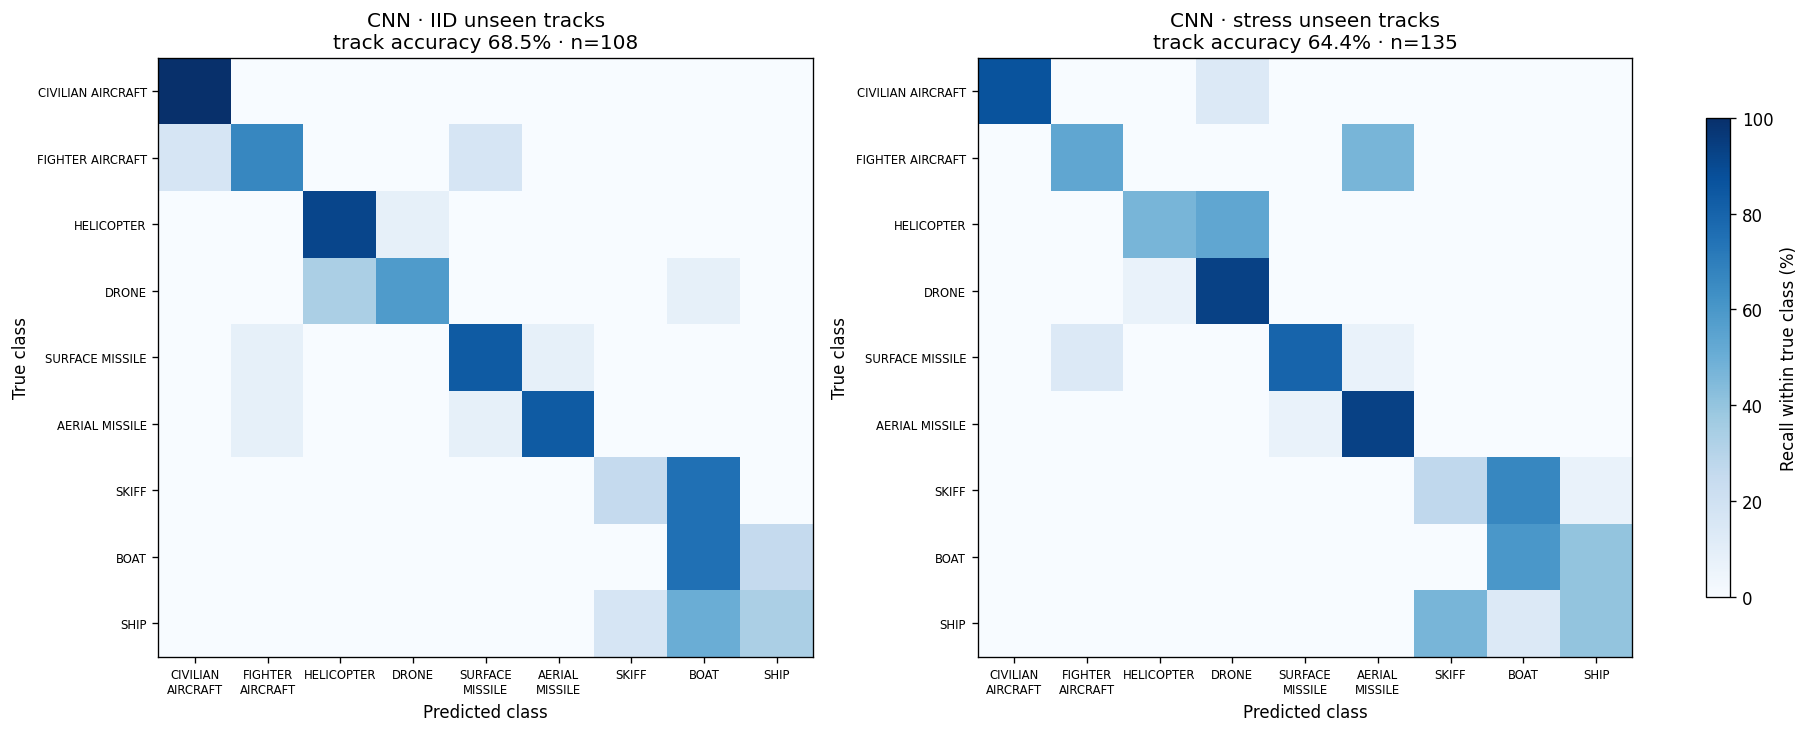

In [8]:
if not LOAD_SAVED_MODELS:
    # Evaluate at physical-track level. Window metrics are supporting metrics only.
    val_probs = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
    iid_probs = model.predict(X_iid_test, batch_size=BATCH_SIZE, verbose=0)
    stress_probs = model.predict(X_stress_test, batch_size=BATCH_SIZE, verbose=0)

    def track_level_results(probs, meta):
        rows = []
        temp = meta.reset_index(drop=True).copy()
        for tid, idx in temp.groupby("track_no", sort=False).groups.items():
            ix = np.asarray(list(idx), dtype=int)
            p = probs[ix].mean(axis=0)
            rows.append({
                "track_no": tid,
                "true_class": str(temp.loc[ix[0], "true_class"]),
                "predicted_class": str(label_encoder.inverse_transform([int(np.argmax(p))])[0]),
                "mean_model_score_not_calibrated": float(np.max(p)),
                "n_windows": len(ix),
            })
        return pd.DataFrame(rows)

    cnn_val_results = track_level_results(val_probs, meta_val)
    iid_track_results = track_level_results(iid_probs, meta_iid_test)
    stress_track_results = track_level_results(stress_probs, meta_stress_test)

    def metric_row(model_name, split_name, results):
        yt = results["true_class"]
        yp = results["predicted_class"]
        return {
            "model": model_name, "split": split_name,
            "track_accuracy": float(accuracy_score(yt, yp)),
            "macro_f1": float(f1_score(yt, yp, labels=CLASSES, average="macro", zero_division=0)),
            "balanced_accuracy": float(balanced_accuracy_score(yt, yp)),
            "n_tracks": int(len(results)),
        }

    cnn_metrics = pd.DataFrame([
        metric_row("CNN-BiGRU-attention", "validation", cnn_val_results),
        metric_row("CNN-BiGRU-attention", "IID test", iid_track_results),
        metric_row("CNN-BiGRU-attention", "stress test", stress_track_results),
    ])
    print("CNN synthetic track-level evaluation (not real-radar accuracy):")
    display(cnn_metrics.style.format({"track_accuracy":"{:.1%}", "macro_f1":"{:.3f}", "balanced_accuracy":"{:.1%}"}))

    # One combined IID/stress confusion-matrix figure; plots are not redrawn per packet.
    fig, axes = plt.subplots(1, 2, figsize=(15, 6), dpi=120, constrained_layout=True)
    for ax, results, title in [(axes[0], iid_track_results, "CNN · IID unseen tracks"),
                               (axes[1], stress_track_results, "CNN · stress unseen tracks")]:
        cm = confusion_matrix(results["true_class"], results["predicted_class"], labels=CLASSES)
        support = cm.sum(axis=1)
        pct = np.divide(cm, support[:, None], out=np.zeros_like(cm, dtype=float), where=support[:, None] != 0) * 100
        im = ax.imshow(pct, cmap="Blues", vmin=0, vmax=100, aspect="auto")
        ax.set_xticks(range(len(CLASSES)), [c.replace("_", "\n") for c in CLASSES], rotation=0, fontsize=7)
        ax.set_yticks(range(len(CLASSES)), [c.replace("_", " ") for c in CLASSES], fontsize=7)
        ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
        acc = accuracy_score(results["true_class"], results["predicted_class"])
        ax.set_title(f"{title}\ntrack accuracy {acc:.1%} · n={len(results)}")
    fig.colorbar(im, ax=axes, shrink=0.8, label="Recall within true class (%)")
    plt.show()

else:
    print("Synthetic CNN evaluation loaded from the saved bundle; skipping re-evaluation/retraining.")


## 6. Load or train ExtraTrees track-summary model

The fitted pipeline (including its imputer) and exact summary-column schema are saved locally under `model_11/` for reuse in future runs.

In [9]:
if not LOAD_SAVED_MODELS:
    # ExtraTrees was the strongest Model-21 baseline in prior runs. Train it on the SAME
    # physical track split used above. No labels/IDs/scenario metadata enter its predictors.
    from sklearn.ensemble import ExtraTreesClassifier
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.metrics import classification_report

    TRACK_SUMMARY_STATS = ("median", "q10", "q90", "std", "delta")

    def summarize_labeled_track(g):
        g = g.sort_values("ntp_sec", kind="stable").tail(SEQUENCE_LENGTH)
        row = {
            "track_no": g["track_no"].iloc[0],
            "true_class": str(g["_true_class"].iloc[0]),
            "scenario_family": str(g["_scenario_family"].iloc[0]),
            "n_packets_used": int(len(g)),
        }
        for col in FEATURE_COLS:
            arr = pd.to_numeric(g[col], errors="coerce").replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
            valid = arr[np.isfinite(arr)]
            if len(valid) == 0:
                vals = {"median": np.nan, "q10": np.nan, "q90": np.nan, "std": np.nan, "delta": np.nan}
            else:
                vals = {
                    "median": float(np.nanmedian(valid)),
                    "q10": float(np.nanquantile(valid, 0.10)),
                    "q90": float(np.nanquantile(valid, 0.90)),
                    "std": float(np.nanstd(valid, ddof=0)),
                    "delta": float(valid[-1] - valid[0]) if len(valid) >= 2 else 0.0,
                }
            for stat, value in vals.items():
                row[f"{col}__{stat}"] = value
        return row

    track_summary_df = pd.DataFrame([
        summarize_labeled_track(g) for _, g in sim_features.groupby("track_no", sort=False)
    ])
    TRACK_SUMMARY_COLS = [c for c in track_summary_df.columns
                           if c not in {"track_no", "true_class", "scenario_family", "n_packets_used"}]
    assert len(TRACK_SUMMARY_COLS) == len(FEATURE_COLS) * len(TRACK_SUMMARY_STATS)
    assert track_summary_df["track_no"].is_unique

    train_tab = track_summary_df[track_summary_df["track_no"].isin(train_ids)].copy()
    val_tab = track_summary_df[track_summary_df["track_no"].isin(val_ids)].copy()
    iid_tab = track_summary_df[track_summary_df["track_no"].isin(iid_test_ids)].copy()
    stress_tab = track_summary_df[track_summary_df["track_no"].isin(stress_test_ids)].copy()
    assert set(train_tab.track_no).isdisjoint(set(val_tab.track_no))
    assert set(train_tab.track_no).isdisjoint(set(iid_tab.track_no))
    assert set(train_tab.track_no).isdisjoint(set(stress_tab.track_no))

    selected_baseline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", ExtraTreesClassifier(
            n_estimators=400, min_samples_leaf=2, max_features=0.7,
            class_weight="balanced", n_jobs=-1, random_state=SEED
        )),
    ])
    selected_baseline.fit(train_tab[TRACK_SUMMARY_COLS], train_tab["true_class"])

    def predict_tab(tab):
        out = tab[["track_no", "true_class"]].copy()
        out["predicted_class"] = selected_baseline.predict(tab[TRACK_SUMMARY_COLS])
        out["top_score_not_calibrated"] = selected_baseline.predict_proba(tab[TRACK_SUMMARY_COLS]).max(axis=1)
        return out

    et_val_results = predict_tab(val_tab)
    et_iid_results = predict_tab(iid_tab)
    et_stress_results = predict_tab(stress_tab)

    et_metrics = pd.DataFrame([
        metric_row("ExtraTrees track-summary", "validation", et_val_results),
        metric_row("ExtraTrees track-summary", "IID test", et_iid_results),
        metric_row("ExtraTrees track-summary", "stress test", et_stress_results),
    ])
    synthetic_metrics = pd.concat([cnn_metrics, et_metrics], ignore_index=True)
    print("\nCNN vs ExtraTrees — same synthetic physical-track splits:")
    display(synthetic_metrics.style.format({"track_accuracy":"{:.1%}", "macro_f1":"{:.3f}", "balanced_accuracy":"{:.1%}"}))
    print("\nExtraTrees per-class report — IID test:")
    print(classification_report(et_iid_results["true_class"], et_iid_results["predicted_class"], labels=CLASSES, zero_division=0, digits=3))
    print("\nExtraTrees per-class report — stress test:")
    print(classification_report(et_stress_results["true_class"], et_stress_results["predicted_class"], labels=CLASSES, zero_division=0, digits=3))
    print("Reminder: these are synthetic-only metrics. ExtraTrees is an additional candidate; it does not replace the CNN replay.")

else:
    print("✅ Using the saved ExtraTrees model; skipping training.")



CNN vs ExtraTrees — same synthetic physical-track splits:


,model,split,track_accuracy,macro_f1,balanced_accuracy,n_tracks
0,CNN-BiGRU-attention,validation,66.7%,0.653,66.7%,108
1,CNN-BiGRU-attention,IID test,68.5%,0.677,68.5%,108
2,CNN-BiGRU-attention,stress test,64.4%,0.638,64.4%,135
3,ExtraTrees track-summary,validation,84.3%,0.831,84.3%,108
4,ExtraTrees track-summary,IID test,75.9%,0.755,75.9%,108
5,ExtraTrees track-summary,stress test,80.0%,0.795,80.0%,135



ExtraTrees per-class report — IID test:
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT      0.857     1.000     0.923        12
 FIGHTER_AIRCRAFT      0.875     0.583     0.700        12
       HELICOPTER      0.706     1.000     0.828        12
            DRONE      0.875     0.583     0.700        12
  SURFACE_MISSILE      0.786     0.917     0.846        12
   AERIAL_MISSILE      1.000     0.917     0.957        12
            SKIFF      0.636     0.583     0.609        12
             BOAT      0.462     0.500     0.480        12
             SHIP      0.750     0.750     0.750        12

         accuracy                          0.759       108
        macro avg      0.772     0.759     0.755       108
     weighted avg      0.772     0.759     0.755       108


ExtraTrees per-class report — stress test:
                   precision    recall  f1-score   support

CIVILIAN_AIRCRAFT      1.000     0.933     0.966        15
 FIGHTER_AIRCRAFT      0.8

In [10]:
# ============================================================
# SAVE MODEL + PREPROCESSING + SCHEMA LOCALLY UNDER ./model_11/
# Writes only on first setup or when FORCE_RETRAIN=True.
# ============================================================
if not LOAD_SAVED_MODELS:
    from sklearn.metrics import classification_report
    ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    model.save(ARTIFACT_DIR / "cnn_model.keras")
    joblib.dump({
        "imputer": imputer,
        "scaler": scaler,
        "label_encoder": label_encoder,
    }, ARTIFACT_DIR / "preprocessing.joblib", compress=3)
    joblib.dump(selected_baseline, ARTIFACT_DIR / "extratrees_model.joblib", compress=3)

    per_class_rows_for_bundle = []
    for model_name, split_name, eval_df in [
        ("CNN-BiGRU-attention", "validation", cnn_val_results),
        ("CNN-BiGRU-attention", "IID test", iid_track_results),
        ("CNN-BiGRU-attention", "stress test", stress_track_results),
        ("ExtraTrees track-summary", "validation", et_val_results),
        ("ExtraTrees track-summary", "IID test", et_iid_results),
        ("ExtraTrees track-summary", "stress test", et_stress_results),
    ]:
        report = classification_report(
            eval_df["true_class"], eval_df["predicted_class"], labels=CLASSES,
            output_dict=True, zero_division=0
        )
        for cls in CLASSES:
            per_class_rows_for_bundle.append({
                "model": model_name, "split": split_name, "class": cls,
                "precision": report[cls]["precision"],
                "recall": report[cls]["recall"],
                "f1": report[cls]["f1-score"],
                "support": report[cls]["support"],
            })
    per_class_metrics = pd.DataFrame(per_class_rows_for_bundle)
    joblib.dump({
        "synthetic_metrics": synthetic_metrics,
        "per_class_metrics": per_class_metrics,
    }, ARTIFACT_DIR / "evaluation_reports.joblib", compress=3)

    bundle_metadata = {
        "bundle_version": BUNDLE_VERSION,
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "tensorflow_version": tf.__version__,
        "sklearn_version": sklearn.__version__,
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__,
        "feature_cols": FEATURE_COLS,
        "sequence_length": int(SEQUENCE_LENGTH),
        "track_summary_stats": list(TRACK_SUMMARY_STATS),
        "track_summary_cols": list(TRACK_SUMMARY_COLS),
        "label_classes": list(label_encoder.classes_),
        "cnn_output_note": "Scores are uncalibrated synthetic-model scores.",
        "extratrees_output_note": "Tree-vote fractions are not calibrated probabilities.",
        "training_data": "synthetic-only",
        "artifact_layout": "portable local folder ./model_11/",
    }
    (ARTIFACT_DIR / "bundle_metadata.json").write_text(json.dumps(bundle_metadata, indent=2))

    (ARTIFACT_DIR / "README.txt").write_text(
        "RADAR MODEL BUNDLE — LOCAL / PORTABLE\n"
        "\nKeep this entire model_11 folder beside the notebook.\n"
        "cnn_model.keras: trained CNN sequence model.\n"
        "preprocessing.joblib: imputer, scaler, and class encoder.\n"
        "extratrees_model.joblib: fitted ExtraTrees pipeline and its imputer.\n"
        "evaluation_reports.joblib: saved synthetic evaluation tables.\n"
        "bundle_metadata.json: schema, class order, package versions, and bundle version.\n"
        "outputs/: one Excel results workbook and research dashboard files after inference.\n"
        "\nThe notebook requires compatible NumPy, pandas, scikit-learn, TensorFlow, joblib,\n"
        "matplotlib, and openpyxl installations. Plotly is optional. No network is required\n"
        "at runtime if dependencies are installed and the models are present.\n"
        "Colab /content is temporary; local disk is persistent.\n"
    )
    (ARTIFACT_DIR / "requirements_offline.txt").write_text(
        f"tensorflow=={tf.__version__}\nscikit-learn=={sklearn.__version__}\n"
        f"numpy=={np.__version__}\npandas=={pd.__version__}\n"
        f"joblib=={joblib.__version__}\nmatplotlib=={plt.matplotlib.__version__}\nopenpyxl\n# Optional: interactive HTML dashboard\nplotly\n"
    )
    print(f"\n✅ Saved both trained models and all preprocessing/schema files in: {ARTIFACT_DIR}")
    print("Core files: cnn_model.keras | preprocessing.joblib | extratrees_model.joblib | bundle_metadata.json | evaluation_reports.joblib")
    print("This folder can be copied as-is with the notebook to another PC that has compatible Python packages installed.")
else:
    print(f"\n✅ Reused saved models from {ARTIFACT_DIR}. No training and no model files rewritten.")


✅ Saved both trained models and all preprocessing/schema files in: /content/model_11
Core files: cnn_model.keras | preprocessing.joblib | extratrees_model.joblib | bundle_metadata.json | evaluation_reports.joblib
This folder can be copied as-is with the notebook to another PC that has compatible Python packages installed.


## 7. Load a real radar CSV for inference

The CSV is used only for inference. Model files load from the local `model_11/` folder; the input CSV is not used to train either model.

In [11]:
# Upload/select the REAL, unlabelled radar CSV for inference. This cell never trains on the real CSV.
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError("No CSV uploaded. Upload radar_data.csv and rerun this cell.")
    CSV_PATH = Path(next(iter(uploaded.keys())))
except ImportError:
    CSV_PATH = Path(input("Enter path to the real radar CSV (e.g. radar_data.csv): ").strip().strip('"')).expanduser()
if not CSV_PATH.exists():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}")
# sep=None lets pandas infer comma-delimited CSV or tab-delimited pasted text files.
raw_csv = pd.read_csv(CSV_PATH, sep=None, engine="python")
if len(raw_csv.columns) == 1 and isinstance(raw_csv.columns[0], str) and "\t" in raw_csv.columns[0]:
    # Defensive fallback for text pasted with literal tab separators.
    raw_csv = pd.read_csv(CSV_PATH, sep="\t")
if "track_no" not in raw_csv.columns:
    raw_csv["track_no"] = 1
if "ntp_sec" not in raw_csv.columns:
    raw_csv["ntp_sec"] = np.arange(len(raw_csv), dtype=float) * SAMPLE_SECONDS
raw_csv = raw_csv.dropna(subset=["track_no", "ntp_sec"]).copy().reset_index(drop=True)
# Stable row ID lets us compute each track's causal rolling/cumulative features once,
# then replay those rows in global timestamp order without mixing track histories.
raw_csv["_packet_id"] = np.arange(len(raw_csv), dtype=np.int64)
print("CSV:", CSV_PATH, "| rows:", len(raw_csv), "| tracks:", raw_csv.track_no.nunique())
print("Target labels from CSV used: NO")
print("\nCoordinate audit before any mapping:")
coordinate_report = coordinate_frame_audit(raw_csv)
if CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    # Explicitly opt in only after checking the ICD. Never infer this mapping from correlation alone.
    for a, b in [("vel_x", "vel_y"), ("accel_x", "accel_y"),
                 ("std_dev_vx", "std_dev_vy"), ("std_dev_ax", "std_dev_ay")]:
        if a in raw_csv.columns and b in raw_csv.columns:
            raw_csv[[a, b]] = raw_csv[[b, a]].to_numpy()
    print("⚠️ Applied the explicitly configured X/Y velocity/acceleration swap. Verify against ICD documentation.")
    coordinate_report = coordinate_frame_audit(raw_csv)
coordinate_mapping_suspect = False
if not coordinate_report.empty and {"reported_velocity_axis", "corr_with_dpos_x", "corr_with_dpos_y"}.issubset(coordinate_report.columns):
    rx = coordinate_report[coordinate_report["reported_velocity_axis"] == "x"]
    ry = coordinate_report[coordinate_report["reported_velocity_axis"] == "y"]
    if len(rx) and len(ry):
        rx, ry = rx.iloc[0], ry.iloc[0]
        coordinate_mapping_suspect = bool(
            (pd.notna(rx["corr_with_dpos_y"]) and (pd.isna(rx["corr_with_dpos_x"]) or rx["corr_with_dpos_y"] > rx["corr_with_dpos_x"] + 0.25))
            or (pd.notna(ry["corr_with_dpos_x"]) and (pd.isna(ry["corr_with_dpos_y"]) or ry["corr_with_dpos_x"] > ry["corr_with_dpos_y"] + 0.25))
        )
if coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP:
    print("ℹ️ Cross-axis derivative pattern retained as a diagnostic note. No automatic remapping and no classification gate are applied.")
unc_present = [c for c in UNCERTAINTY_COLS if c in raw_csv.columns]
if unc_present:
    print(f"Uncertainty/covariance columns present: {len(unc_present)}; retained for diagnostics only.")
real_features = robust_feature_extractor(raw_csv)

real_matrix = imputer.transform(real_features[FEATURE_COLS])
real_scaled_array = np.clip(scaler.transform(real_matrix), -8, 8)
shift_share = np.mean(np.abs(real_scaled_array) > 5.0, axis=0)
shift_report = pd.Series(shift_share, index=FEATURE_COLS).sort_values(ascending=False)
print("\nFeatures with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):")
print(shift_report[shift_report > 0.10].to_string() if (shift_report > 0.10).any() else "None detected by this simple check.")
print("⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.")

Saving radar_data.csv to radar_data.csv
CSV: radar_data.csv | rows: 82 | tracks: 1
Target labels from CSV used: NO

Coordinate audit before any mapping:
Position/velocity axis audit (diagnostic only; no automatic axis swapping):


,reported_velocity_axis,corr_with_dpos_x,corr_with_dpos_y,corr_with_dpos_z
0,x,-0.024,0.998,-0.027
1,y,0.997,0.035,-0.030
2,z,0.105,0.053,0.593


ℹ️ Cross-axis pattern: vel_x aligns more with d(pos_y) than d(pos_x). No coordinates are changed; this is recorded as a diagnostic because signed horizontal X/Y features are not used by this classifier.
ℹ️ Cross-axis pattern: vel_y aligns more with d(pos_x) than d(pos_y). No coordinates are changed; this is recorded as a diagnostic because signed horizontal X/Y features are not used by this classifier.
ℹ️ Cross-axis derivative pattern retained as a diagnostic note. No automatic remapping and no classification gate are applied.
Uncertainty/covariance columns present: 12; retained for diagnostics only.

Features with >10% of rows beyond 5 robust-scaler units (diagnostic, not a verdict):
None detected by this simple check.
⚠️ No outlier warning does NOT prove the real data matches synthetic training or that model scores are calibrated.


## 8. Append-only packet replay — CNN and ExtraTrees together

The CNN updates its rolling 30-packet sequence per packet. ExtraTrees updates its rolling 30-packet track summary per packet and remains in `WARMING_UP` until each track has 30 packets. The text replay is deliberately paced (`PLAYBACK_DELAY` in the setup cell) and plots are drawn only after replay ends—no blinking/redrawn plots during the feed. Model scores and tree-vote fractions are uncalibrated.

In [12]:
# 7. LIVE FEED — append-only packet-by-packet replay (NO blinking dashboard/plots)
import time
from collections import deque

EMA_ALPHA = 0.12                  # score smoothing for display; not probability calibration
MIN_STABLE_STREAK = 3
LIVE_HISTORY_POINTS = 240
FOCUS_TRACK = None                # None = track with most packets; or specify an exact track_no

class_order = list(label_encoder.classes_)
et_classes = np.asarray(selected_baseline.named_steps["model"].classes_, dtype=str)
ET_EMA_ALPHA = 0.25  # smoothing of rolling tree-vote scores for display only, not calibration
TRACK_SUMMARY_STATS = ("median", "q10", "q90", "std", "delta")

def summarize_feature_window(feature_window):
    """Match the exact final-30-packet summary schema used to train ExtraTrees."""
    frame = pd.DataFrame(list(feature_window))
    row = {}
    for col in FEATURE_COLS:
        arr = pd.to_numeric(frame[col], errors="coerce").replace([np.inf, -np.inf], np.nan).to_numpy(dtype=float)
        valid = arr[np.isfinite(arr)]
        if len(valid) == 0:
            vals = {"median": np.nan, "q10": np.nan, "q90": np.nan, "std": np.nan, "delta": np.nan}
        else:
            vals = {
                "median": float(np.nanmedian(valid)),
                "q10": float(np.nanquantile(valid, 0.10)),
                "q90": float(np.nanquantile(valid, 0.90)),
                "std": float(np.nanstd(valid, ddof=0)),
                "delta": float(valid[-1] - valid[0]) if len(valid) >= 2 else 0.0,
            }
        for stat in TRACK_SUMMARY_STATS:
            row[f"{col}__{stat}"] = vals[stat]
    return pd.DataFrame([row]).reindex(columns=TRACK_SUMMARY_COLS)

feature_lookup = real_features.set_index("_packet_id", drop=False)
scaled_lookup = {int(pid): np.asarray(vec, dtype=np.float32)
                 for pid, vec in zip(real_features["_packet_id"].astype(int), real_scaled_array)}
ordered = raw_csv.sort_values("ntp_sec", kind="stable").reset_index(drop=True)
track_packet_counts = ordered.groupby("track_no", sort=False).size()
if FOCUS_TRACK is None:
    focus_track = track_packet_counts.idxmax()
else:
    if FOCUS_TRACK not in set(ordered["track_no"].tolist()):
        raise ValueError(f"FOCUS_TRACK={FOCUS_TRACK!r} not found in CSV track_no values")
    focus_track = FOCUS_TRACK

stream_rows = []
track_states = {}
# Keep short-track demos visibly paced, but cap delays for very large files.
REPLAY_TIME_BUDGET_SECONDS = 90.0
LIVE_DELAY = min(float(PLAYBACK_DELAY), REPLAY_TIME_BUDGET_SECONDS / max(len(ordered), 1))
print(f'Replay pacing: requested={PLAYBACK_DELAY:.3f}s, effective={LIVE_DELAY:.4f}s/packet; approximate delay budget <= {REPLAY_TIME_BUDGET_SECONDS:.0f}s.', flush=True)
print("📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end", flush=True)
print(f"File: {CSV_PATH} | packets: {len(ordered)} | tracks: {ordered['track_no'].nunique()} | focus track: {focus_track}", flush=True)
print("Scores are uncalibrated synthetic-model scores; input CSV labels are never used.\n", flush=True)

for packet_idx, packet in ordered.iterrows():
    tid = packet["track_no"]
    packet_id = int(packet["_packet_id"])
    scaled_row = scaled_lookup[packet_id]
    feat_row = feature_lookup.loc[packet_id]

    state = track_states.get(tid)
    if state is None:
        state = {
            "scaled_window": deque(maxlen=SEQUENCE_LENGTH),
            "et_feature_window": deque(maxlen=SEQUENCE_LENGTH),
            "et_ema": None, "et_candidate": None, "et_candidate_streak": 0,
            "et_stable": "WARMING_UP", "et_last_candidate": "WARMING_UP",
            "et_last_score": np.nan, "et_last_status": "WARMING_UP — NEED 30 PACKETS",
            "history": deque(maxlen=LIVE_HISTORY_POINTS),
            "ema": None, "count": 0, "candidate": None, "candidate_streak": 0,
            "stable": "WARMING_UP", "last_seen": float(packet["ntp_sec"]),
            "last_window_candidate": "WARMING_UP", "last_window_score": np.nan,
            "last_track_candidate": "WARMING_UP", "last_track_score": np.nan,
            "last_margin": np.nan, "last_status": "PROVISIONAL — SHORT HISTORY",
            "last_speed": np.nan, "last_altitude": np.nan, "last_accel": np.nan,
        }

    # Each track has its own CNN sequence buffer and ExtraTrees summary buffer.
    # Interleaved tracks never share packet histories.
    state["et_feature_window"].append({
        col: (float(feat_row[col]) if col in feat_row.index and pd.notna(feat_row[col]) else np.nan)
        for col in FEATURE_COLS
    })
    state["scaled_window"].append(scaled_row)
    available = np.asarray(state["scaled_window"], dtype=np.float32)
    warmup = state["count"] + 1 < SEQUENCE_LENGTH
    if len(available) < SEQUENCE_LENGTH:
        sequence = np.concatenate([np.repeat(available[:1], SEQUENCE_LENGTH-len(available), axis=0), available], axis=0)
    else:
        sequence = available[-SEQUENCE_LENGTH:]

    p = np.asarray(model.predict(sequence[None, ...], verbose=0)[0], dtype=float)
    p = np.clip(p, 1e-8, 1.0); p /= p.sum()
    window_idx = int(np.argmax(p))
    window_candidate = class_order[window_idx]
    window_score = float(p[window_idx])
    if state["ema"] is None:
        state["ema"] = p.copy()
    else:
        state["ema"] = (1.0-EMA_ALPHA)*state["ema"] + EMA_ALPHA*p
        state["ema"] /= state["ema"].sum()
    track_p = state["ema"].copy()
    rank = np.argsort(track_p)[::-1]
    track_idx = int(rank[0]); track_candidate = class_order[track_idx]
    track_score = float(track_p[track_idx])
    margin = float(track_p[rank[0]] - track_p[rank[1]])

    if track_candidate == state["candidate"]:
        state["candidate_streak"] += 1
    else:
        state["candidate"] = track_candidate
        state["candidate_streak"] = 1
    if not warmup and state["candidate_streak"] >= MIN_STABLE_STREAK and track_score >= 0.40 and margin >= 0.08:
        state["stable"] = track_candidate

    if warmup:
        status = "PROVISIONAL — SHORT HISTORY"
    elif track_score < 0.40 or margin < 0.08:
        status = "LOW / AMBIGUOUS MODEL EVIDENCE"
    else:
        status = "SYNTHETIC-MODEL CANDIDATE — UNVERIFIED"

    # ExtraTrees rolling replay: its training input is a summary of the most recent 30
    # packets, so it warms up independently and then emits one candidate at each packet.
    et_n = len(state["et_feature_window"])
    et_window_candidate = "WARMING_UP"
    et_track_candidate = "WARMING_UP"
    et_window_score = np.nan
    et_track_score = np.nan
    et_margin = np.nan
    et_runner_up_class = "WARMING_UP"
    et_runner_up_score = np.nan
    et_candidate_3_class = "WARMING_UP"
    et_candidate_3_score = np.nan
    et_status = f"WARMING_UP — {et_n}/{SEQUENCE_LENGTH} PACKETS"
    et_stable = state["et_stable"]
    if et_n >= SEQUENCE_LENGTH:
        et_x = summarize_feature_window(state["et_feature_window"])
        et_raw = np.asarray(selected_baseline.predict_proba(et_x)[0], dtype=float)
        et_raw = np.clip(et_raw, 1e-8, 1.0)
        et_raw = et_raw / et_raw.sum()
        et_window_candidate = str(et_classes[int(np.argmax(et_raw))])
        et_window_score = float(np.max(et_raw))
        if state["et_ema"] is None:
            state["et_ema"] = et_raw.copy()
        else:
            state["et_ema"] = (1.0 - ET_EMA_ALPHA) * state["et_ema"] + ET_EMA_ALPHA * et_raw
            state["et_ema"] = state["et_ema"] / state["et_ema"].sum()
        et_smoothed = state["et_ema"]
        et_rank = np.argsort(et_smoothed)[::-1]
        et_track_candidate = str(et_classes[int(et_rank[0])])
        et_track_score = float(et_smoothed[et_rank[0]])
        et_margin = float(et_smoothed[et_rank[0]] - et_smoothed[et_rank[1]])
        et_runner_up_class = str(et_classes[int(et_rank[1])])
        et_runner_up_score = float(et_smoothed[et_rank[1]])
        if len(et_rank) >= 3:
            et_candidate_3_class = str(et_classes[int(et_rank[2])])
            et_candidate_3_score = float(et_smoothed[et_rank[2]])
        if et_track_candidate == state["et_candidate"]:
            state["et_candidate_streak"] += 1
        else:
            state["et_candidate"] = et_track_candidate
            state["et_candidate_streak"] = 1
        if et_track_score >= 0.40 and et_margin >= 0.08 and state["et_candidate_streak"] >= MIN_STABLE_STREAK:
            state["et_stable"] = et_track_candidate
            et_stable = et_track_candidate
        if et_track_score < 0.40 or et_margin < 0.08:
            et_status = "LOW / AMBIGUOUS TREE-VOTE EVIDENCE"
        elif state["et_candidate_streak"] < MIN_STABLE_STREAK:
            et_status = "CANDIDATE SETTLING"
        else:
            et_status = "SYNTHETIC-MODEL CANDIDATE — UNVERIFIED"
    state["et_last_candidate"] = et_track_candidate
    state["et_last_score"] = et_track_score
    state["et_last_status"] = et_status

    getnum = lambda col: float(feat_row[col]) if col in feat_row.index and pd.notna(feat_row[col]) else np.nan
    speed, altitude, acceleration = getnum("vel_mag"), getnum("pos_z"), getnum("accel_mag")
    state["count"] += 1
    state["last_seen"] = float(packet["ntp_sec"])
    state["last_window_candidate"] = window_candidate
    state["last_window_score"] = window_score
    state["last_track_candidate"] = track_candidate
    state["last_track_score"] = track_score
    state["last_margin"] = margin
    state["last_status"] = status
    state["last_speed"] = speed; state["last_altitude"] = altitude; state["last_accel"] = acceleration
    hist_row = {
        "ntp_sec": float(packet["ntp_sec"]), "window_candidate": window_candidate,
        "window_score": window_score, "track_candidate": track_candidate,
        "track_score": track_score, "stable_hypothesis": state["stable"],
        "speed": speed, "altitude": altitude, "acceleration": acceleration,
    }
    hist_row.update({f"track_score_{c}": float(track_p[j]) for j, c in enumerate(class_order)})
    state["history"].append(hist_row)
    track_states[tid] = state

    row = {
        "track_no": tid, "ntp_sec": float(packet["ntp_sec"]),
        "packet_index_global": packet_idx+1, "packet_index_for_track": state["count"],
        "window_candidate": window_candidate, "window_score_not_calibrated": window_score,
        "track_candidate": track_candidate, "track_score_not_calibrated": track_score,
        "top2_margin_not_calibrated": margin, "stable_hypothesis": state["stable"],
        "status": status, "warmup": warmup, "speed": speed, "altitude": altitude,
        "acceleration": acceleration, "coordinate_mapping_suspect": coordinate_mapping_suspect,
        "pos_x": getnum("pos_x"), "pos_y": getnum("pos_y"), "pos_z": getnum("pos_z"),
        "ExtraTrees_packets_used": et_n,
        "ExtraTrees_window_candidate": et_window_candidate,
        "ExtraTrees_window_score_not_calibrated": et_window_score,
        "ExtraTrees_track_candidate": et_track_candidate,
        "ExtraTrees_top_score_not_calibrated": et_track_score,
        "ExtraTrees_top2_margin_not_calibrated": et_margin,
        "ExtraTrees_candidate_2": et_runner_up_class,
        "ExtraTrees_score_2_not_calibrated": et_runner_up_score,
        "ExtraTrees_candidate_3": et_candidate_3_class,
        "ExtraTrees_score_3_not_calibrated": et_candidate_3_score,
        "ExtraTrees_stable_hypothesis": et_stable,
        "ExtraTrees_status": et_status,
        "ground_truth": "UNLABELLED — not available",
    }
    for j, c in enumerate(class_order):
        row[f"window_score_{c}"] = float(p[j])
        row[f"track_score_{c}"] = float(track_p[j])
    # Expose every smoothed ExtraTrees vote fraction for transparent plotting/export.
    # These are uncalibrated model scores, not probabilities. They stay NaN during warm-up.
    for j, c in enumerate(et_classes):
        row[f"ExtraTrees_score_{c}"] = (
            float(state["et_ema"][j]) if state["et_ema"] is not None else np.nan
        )
    stream_rows.append(row)

    # Crucially: plain print only. No clear_output, dashboard redraw, display(), or plotting here.
    if PRINT_EVERY_N_PACKETS > 0 and ((packet_idx+1) % PRINT_EVERY_N_PACKETS == 0):
        if et_n < SEQUENCE_LENGTH:
            et_display = f"ExtraTrees=WARMING_UP ({et_n}/{SEQUENCE_LENGTH})"
        else:
            et_display = f"ExtraTrees={et_track_candidate} ({et_track_score:.1%}, vote score)"
        ts_display = f"{float(packet['ntp_sec']):.1f}s"
        cnn_margin_display = f"Δ={margin:.1%}" if np.isfinite(margin) else "Δ=—"
        et_margin_display = f"Δ={et_margin:.1%}" if np.isfinite(et_margin) else "Δ=—"
        print(
            f"📡 {packet_idx+1:04d}/{len(ordered):04d}  t={ts_display:<14} track={str(tid):<8} | "
            f"CNN  {track_candidate:<20} {track_score:>6.1%} {cnn_margin_display:<8} | "
            f"ET   {et_track_candidate:<20} {et_track_score:>6.1%} {et_margin_display:<8} | "
            f"{status} / {et_status}", flush=True
        )
        if PLAYBACK_DELAY > 0:
            time.sleep(LIVE_DELAY)

stream = pd.DataFrame(stream_rows).sort_values("ntp_sec", kind="stable").reset_index(drop=True)

# Integrity checks: every input packet appears exactly once, and per-track counts are unchanged.
assert len(stream) == len(raw_csv), f"Output rows ({len(stream)}) != input packets ({len(raw_csv)})"
input_counts = raw_csv.groupby("track_no", sort=False).size().to_dict()
output_counts = stream.groupby("track_no", sort=False).size().to_dict()
assert input_counts == output_counts, "Per-track packet counts changed during replay"
assert stream.groupby("track_no")["packet_index_for_track"].max().to_dict() == input_counts
print("\n✅ Multi-track integrity checks passed.", flush=True)
print(f"✅ Replay integrity passed: {len(stream)} input packets -> {len(stream)} packet predictions", flush=True)

Replay pacing: requested=0.120s, effective=0.1200s/packet; approximate delay budget <= 90s.
📡 LIVE RADAR REPLAY — append-only feed; plots are deferred until the end
File: radar_data.csv | packets: 82 | tracks: 1 | focus track: 1
Scores are uncalibrated synthetic-model scores; input CSV labels are never used.

📡 0001/0082  t=3991182426.0s  track=1.0      | CNN  SURFACE_MISSILE       44.4% Δ=1.0%   | ET   WARMING_UP             nan% Δ=—      | PROVISIONAL — SHORT HISTORY / WARMING_UP — 1/30 PACKETS
📡 0002/0082  t=3991182434.0s  track=1.0      | CNN  SURFACE_MISSILE       43.9% Δ=0.1%   | ET   WARMING_UP             nan% Δ=—      | PROVISIONAL — SHORT HISTORY / WARMING_UP — 2/30 PACKETS
📡 0003/0082  t=3991182444.0s  track=1.0      | CNN  AERIAL_MISSILE        44.5% Δ=0.9%   | ET   WARMING_UP             nan% Δ=—      | PROVISIONAL — SHORT HISTORY / WARMING_UP — 3/30 PACKETS
📡 0004/0082  t=3991182454.0s  track=1.0      | CNN  AERIAL_MISSILE        44.3% Δ=1.2%   | ET   WARMING_UP          

## 9. Final comparison and one workbook

The final table compares CNN and ExtraTrees per track. A single formatted Excel workbook is saved to `model_11/outputs/`, along with the research dashboard files. No diagnostic CSV pile is produced.

In [13]:
# Final comparison uses the *last live ExtraTrees replay state* for each track.
# This keeps the ExtraTrees candidate in the summary consistent with the packet-by-packet feed.
et_latest = (stream.sort_values("ntp_sec", kind="stable")
             .groupby("track_no", sort=False).tail(1).copy())
et_real_summary = et_latest[[
    "track_no", "ExtraTrees_packets_used", "ExtraTrees_window_candidate",
    "ExtraTrees_window_score_not_calibrated", "ExtraTrees_track_candidate",
    "ExtraTrees_top_score_not_calibrated", "ExtraTrees_candidate_2",
    "ExtraTrees_score_2_not_calibrated", "ExtraTrees_candidate_3",
    "ExtraTrees_score_3_not_calibrated", "ExtraTrees_stable_hypothesis",
    "ExtraTrees_status", "ExtraTrees_top2_margin_not_calibrated"
]].copy()

# Build the CNN track summary from the completed replay (one row per physical track).
summary_rows = []
for tid, g in stream.groupby("track_no", sort=False):
    g = g.sort_values("ntp_sec", kind="stable")
    last = g.iloc[-1]
    valid = g[~g["warmup"]]
    changes = int((valid["window_candidate"] != valid["window_candidate"].shift()).sum() - 1) if len(valid) else 0
    score_cols = [f"track_score_{c}" for c in class_order]
    top = last[score_cols].astype(float).sort_values(ascending=False)
    summary_rows.append({
        "track_no": tid, "packets_processed": len(g),
        "first_timestamp": g["ntp_sec"].iloc[0], "last_timestamp": last["ntp_sec"],
        "latest_window_candidate": last["window_candidate"],
        "final_track_candidate": last["track_candidate"],
        "final_stable_hypothesis": last["stable_hypothesis"],
        "top_model_score_not_calibrated": float(top.iloc[0]),
        "runner_up_class": str(top.index[1].replace("track_score_", "")),
        "runner_up_score_not_calibrated": float(top.iloc[1]),
        "window_candidate_changes": max(0, changes), "status": last["status"],
        "ground_truth": "UNLABELLED — not available",
    })
track_summary = pd.DataFrame(summary_rows).sort_values("track_no", key=lambda s: s.astype(str), kind="stable")

# Rename the latest ExtraTrees replay columns for the compact track-level comparison table.
et_real_summary = et_real_summary.rename(columns={
    "ExtraTrees_packets_used": "ExtraTrees_packets_used",
    "ExtraTrees_window_candidate": "ExtraTrees_latest_window_candidate",
    "ExtraTrees_window_score_not_calibrated": "ExtraTrees_latest_window_score_not_calibrated",
    "ExtraTrees_track_candidate": "ExtraTrees_track_candidate",
    "ExtraTrees_top_score_not_calibrated": "ExtraTrees_top_score_not_calibrated",
    "ExtraTrees_stable_hypothesis": "ExtraTrees_stable_hypothesis",
    "ExtraTrees_status": "ExtraTrees_status",
})
# CNN summary was created after append-only replay. Merge by track identifier, never by row order.
final_results = track_summary.merge(et_real_summary, on="track_no", how="left", validate="one_to_one")
final_results["CNN_and_ExtraTrees_agree"] = (
    (final_results["final_track_candidate"].astype(str) == final_results["ExtraTrees_track_candidate"].astype(str))
    & (final_results["ExtraTrees_packets_used"].fillna(0).astype(int) >= SEQUENCE_LENGTH)
)

def final_status(r):
    if int(r["packets_processed"]) < SEQUENCE_LENGTH or int(r.get("ExtraTrees_packets_used", 0) or 0) < SEQUENCE_LENGTH:
        return "LOW HISTORY — ExtraTrees requires 30 packets"
    if "LOW / AMBIGUOUS" in str(r["status"]) or "LOW / AMBIGUOUS" in str(r.get("ExtraTrees_status", "")):
        return "LOW / AMBIGUOUS MODEL EVIDENCE"
    if bool(r["CNN_and_ExtraTrees_agree"]):
        return "MODEL AGREEMENT — CANDIDATES UNVERIFIED"
    return "MODEL DISAGREEMENT — REVIEW CANDIDATES"

final_results["combined_status"] = final_results.apply(final_status, axis=1)
final_results["ground_truth"] = "UNLABELLED — not available"
final_results["horizontal_component_diagnostic"] = (
    "Cross-axis derivative pattern observed; no automatic remapping applied"
    if coordinate_mapping_suspect and not CONFIRM_VELOCITY_ACCEL_XY_SWAP
    else "No cross-axis derivative warning from this check"
)

# One compact status table in notebook output.
visible_cols = [
    "track_no", "packets_processed", "final_track_candidate", "final_stable_hypothesis",
    "top_model_score_not_calibrated", "ExtraTrees_window_candidate",
    "ExtraTrees_track_candidate", "ExtraTrees_top_score_not_calibrated",
    "ExtraTrees_candidate_2", "ExtraTrees_score_2_not_calibrated",
    "ExtraTrees_candidate_3", "ExtraTrees_score_3_not_calibrated",
    "ExtraTrees_stable_hypothesis", "ExtraTrees_status", "CNN_and_ExtraTrees_agree",
    "combined_status", "horizontal_component_diagnostic"
]
print("\nFINAL RADAR TRACK CANDIDATES — candidates only, not verified identities")
display(final_results[[c for c in visible_cols if c in final_results.columns]].sort_values("track_no", key=lambda s: s.astype(str)).reset_index(drop=True))

# Synthetic per-class metrics were created during initial training and saved with the bundle.
# A fresh inference runtime loads that exact report; it does not retrain just to recreate metrics.

# Save one formatted workbook under model_11/outputs/.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_FILE = OUTPUT_DIR / "radar_final_results.xlsx"
with pd.ExcelWriter(RESULTS_FILE, engine="openpyxl") as writer:
    final_results.to_excel(writer, sheet_name="Track Results", index=False)
    stream.to_excel(writer, sheet_name="Packet Replay", index=False)
    synthetic_metrics.to_excel(writer, sheet_name="Synthetic Evaluation", index=False)
    per_class_metrics.to_excel(writer, sheet_name="Per-class Metrics", index=False)

# Readability formatting: frozen headers, filters, consistent header styling, restrained widths.
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter
from openpyxl import load_workbook
_wb = load_workbook(RESULTS_FILE)
for _ws in _wb.worksheets:
    _ws.freeze_panes = "A2"
    _ws.auto_filter.ref = _ws.dimensions
    for _cell in _ws[1]:
        _cell.font = Font(bold=True, color="FFFFFF")
        _cell.fill = PatternFill("solid", fgColor="17324D")
        _cell.alignment = Alignment(wrap_text=True, vertical="center")
    _ws.row_dimensions[1].height = 30
    for _col in _ws.columns:
        _letter = get_column_letter(_col[0].column)
        _sample = [len(str(c.value)) for c in _col[:250] if c.value is not None]
        _ws.column_dimensions[_letter].width = min(max(max(_sample, default=10) + 2, 12), 32)
_wb.save(RESULTS_FILE)

print(f"\n✅ Saved ONE results workbook: {RESULTS_FILE.resolve()}")
print("Sheets: Track Results | Packet Replay (CNN + ExtraTrees live) | Synthetic Evaluation | Per-class Metrics")
print(f"Model artifacts are stored locally under: {ARTIFACT_DIR}")
print("No diagnostic CSVs, ZIP bundles, or Drive dependency are used.")
print("Important: model scores/vote fractions are uncalibrated; real labels are unavailable. ExtraTrees updates after 30 packets per track. No coordinate remapping is applied automatically.")
try:
    from google.colab import files
    files.download(str(RESULTS_FILE))
except Exception:
    print(f"Automatic Colab download unavailable here; retrieve the workbook from {RESULTS_FILE.resolve()}.")



FINAL RADAR TRACK CANDIDATES — candidates only, not verified identities


,track_no,packets_processed,final_track_candidate,final_stable_hypothesis,top_model_score_not_calibrated,ExtraTrees_track_candidate,ExtraTrees_top_score_not_calibrated,ExtraTrees_candidate_2,ExtraTrees_score_2_not_calibrated,ExtraTrees_candidate_3,ExtraTrees_score_3_not_calibrated,ExtraTrees_stable_hypothesis,ExtraTrees_status,CNN_and_ExtraTrees_agree,combined_status,horizontal_component_diagnostic
0,1.0,82,FIGHTER_AIRCRAFT,FIGHTER_AIRCRAFT,0.475808,FIGHTER_AIRCRAFT,0.436137,CIVILIAN_AIRCRAFT,0.208514,DRONE,0.167418,FIGHTER_AIRCRAFT,SYNTHETIC-MODEL CANDIDATE — UNVERIFIED,True,MODEL AGREEMENT — CANDIDATES UNVERIFIED,Cross-axis derivative pattern observed; no aut...



✅ Saved ONE results workbook: /content/model_11/outputs/radar_final_results.xlsx
Sheets: Track Results | Packet Replay (CNN + ExtraTrees live) | Synthetic Evaluation | Per-class Metrics
Model artifacts are stored locally under: /content/model_11
No diagnostic CSVs, ZIP bundles, or Drive dependency are used.
Important: model scores/vote fractions are uncalibrated; real labels are unavailable. ExtraTrees updates after 30 packets per track. No coordinate remapping is applied automatically.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Research plots — one plot per cell

A restrained, presentation-ready visual system is used throughout: dark navy by default, with a one-line light-theme option. Each research plot remains in its own cell. Plotly charts support hover, zoom, legend toggles and offline HTML export; an optional trajectory animation adds play/pause and a time slider. Matplotlib remains the fallback. These plots are descriptive, not evidence of real-radar accuracy.

**Theme:** set `PLOT_THEME = "dark"` or `PLOT_THEME = "light"` in the plot setup cell, then rerun the plot cells. **Track:** set `FOCUS_TRACK` in the live setup cell before replay, or change `_focus_id` in the plot setup cell and rerun the plot cells.

In [14]:
# Plot setup — run once; individual charts are in the cells below.
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Visual preference: "dark" (recommended for live demos) or "light" (recommended for papers/printing).
PLOT_THEME = "dark"  # change to "light" and rerun the plot cells for light-background figures
if PLOT_THEME not in {"dark", "light"}:
    raise ValueError("PLOT_THEME must be 'dark' or 'light'.")
PLOTLY_TEMPLATE = "plotly_dark" if PLOT_THEME == "dark" else "plotly_white"
if PLOT_THEME == "dark":
    FIG_BG, AX_BG, GRID_COLOR, TEXT_COLOR = "#0B1220", "#101B2D", "#263449", "#E6EDF7"
    MUTED_TEXT, ACCENT, START_COLOR, END_COLOR = "#9FB0C8", "#48DDF5", "#5CE0A3", "#FF6B7A"
else:
    FIG_BG, AX_BG, GRID_COLOR, TEXT_COLOR = "#FFFFFF", "#FFFFFF", "#DCE3EB", "#1E293B"
    MUTED_TEXT, ACCENT, START_COLOR, END_COLOR = "#64748B", "#087EA4", "#16865B", "#C83E4D"

# Pick focus track using the same rule as the live replay.
if FOCUS_TRACK is not None and stream["track_no"].astype(str).eq(str(FOCUS_TRACK)).any():
    _focus_id = stream.loc[stream["track_no"].astype(str).eq(str(FOCUS_TRACK)), "track_no"].iloc[0]
else:
    _focus_id = stream.groupby("track_no", sort=False).size().idxmax()
_focus = stream[stream["track_no"] == _focus_id].sort_values("ntp_sec", kind="stable").copy()
_focus["packet_for_track"] = np.arange(1, len(_focus) + 1)

_CLASS_PALETTE = {
    "CIVILIAN_AIRCRAFT":"#55B7E8", "FIGHTER_AIRCRAFT":"#FF7185", "HELICOPTER":"#5CE0A3",
    "DRONE":"#FFBE69", "SURFACE_MISSILE":"#B69CFF", "AERIAL_MISSILE":"#FF8A65",
    "SKIFF":"#45D6C5", "BOAT":"#7BA7FF", "SHIP":"#B0BAC8"
}
_CNN_COLOR = "#48DDF5" if PLOT_THEME == "dark" else "#087EA4"
_ET_COLOR = "#C3A6FF" if PLOT_THEME == "dark" else "#7851A9"
_MOTION_COLOR = "#FFBE69" if PLOT_THEME == "dark" else "#B86A00"
_HEIGHT_COLOR = "#5CE0A3" if PLOT_THEME == "dark" else "#16865B"

try:
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False
    print("Plotly not installed: using Matplotlib. For interactive charts/animation, install Plotly in the environment, then rerun this cell.")

# Apply consistent styling to Matplotlib fallback plots.
plt.rcParams.update({
    "figure.facecolor": FIG_BG, "axes.facecolor": AX_BG,
    "axes.edgecolor": GRID_COLOR, "axes.labelcolor": TEXT_COLOR,
    "xtick.color": MUTED_TEXT, "ytick.color": MUTED_TEXT,
    "text.color": TEXT_COLOR, "axes.titlecolor": TEXT_COLOR,
    "grid.color": GRID_COLOR, "savefig.facecolor": FIG_BG,
    "legend.facecolor": AX_BG, "legend.edgecolor": GRID_COLOR,
})

print(f"Theme: {PLOT_THEME.upper()} | Focus track: {_focus_id} | packets: {len(_focus)}")
print(f"Available tracks: {stream['track_no'].nunique()} | Figures saved to: {FIGURE_DIR}")
print("Scores are uncalibrated; synthetic metrics do not establish real-radar accuracy.")

Theme: DARK | Focus track: 1.0 | packets: 82
Available tracks: 1 | Figures saved to: /content/model_11/outputs/figures
Scores are uncalibrated; synthetic metrics do not establish real-radar accuracy.


### Optional overview — compare multiple tracks

Use the legend to show/hide tracks, or hover over the paths to inspect coordinates. This is a compact overview; use the single-track plots below for detailed analysis. The overview is saved as a self-contained HTML file when Plotly is available.

In [15]:
# Optional multi-track overview (visualization only; no model/inference changes)
if PLOTLY_AVAILABLE:
    _track_fig = go.Figure()
    _track_ids = list(stream["track_no"].dropna().drop_duplicates())
    for _idx, _tid in enumerate(_track_ids):
        _td = stream[stream["track_no"] == _tid].sort_values("ntp_sec", kind="stable")
        _xyz2 = _td[["pos_x", "pos_y"]].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
        if len(_xyz2) < 2:
            continue
        _color = list(_CLASS_PALETTE.values())[_idx % len(_CLASS_PALETTE)]
        _track_fig.add_trace(go.Scatter(
            x=_xyz2["pos_x"], y=_xyz2["pos_y"], mode="lines+markers", name=f"Track { _tid }",
            line=dict(color=_color, width=2.5), marker=dict(size=4),
            customdata=np.arange(1, len(_xyz2) + 1),
            hovertemplate="Track: " + str(_tid) + "<br>Packet %{customdata}<br>X: %{x:.2f} m<br>Y: %{y:.2f} m<extra></extra>"
        ))
    _track_fig.update_layout(
        title="Multi-track spatial overview", template=PLOTLY_TEMPLATE,
        paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG,
        font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), height=540,
        xaxis_title="X position (m)", yaxis_title="Y position (m)",
        legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"),
        margin=dict(l=45, r=25, t=75, b=45), hovermode="closest"
    )
    _track_fig.update_xaxes(showgrid=True, gridcolor=GRID_COLOR, zerolinecolor=GRID_COLOR)
    _track_fig.update_yaxes(showgrid=True, gridcolor=GRID_COLOR, zerolinecolor=GRID_COLOR, scaleanchor="x", scaleratio=1)
    _track_fig.write_html(FIGURE_DIR / "00_multitrack_overview.html", include_plotlyjs=True)
    _track_fig.show()
else:
    print("Multi-track interactive overview requires Plotly; skipped because Plotly is unavailable.")

### Plot 1 — CNN vs ExtraTrees score timeline
Hover over points to inspect packet number, candidate, and uncalibrated score. These values are not calibrated probabilities.

In [16]:
# Plot 1: score timeline
if PLOTLY_AVAILABLE:
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_focus["track_score_not_calibrated"], mode="lines", name="CNN top score", line=dict(color=_CNN_COLOR, width=3), customdata=_focus["track_candidate"].astype(str), hovertemplate="Packet %{x}<br>CNN: %{customdata}<br>score: %{y:.1%}<extra></extra>"))
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_focus["ExtraTrees_top_score_not_calibrated"], mode="lines", name="ExtraTrees top vote", line=dict(color=_ET_COLOR, width=3), customdata=_focus["ExtraTrees_track_candidate"].astype(str), hovertemplate="Packet %{x}<br>ExtraTrees: %{customdata}<br>vote fraction: %{y:.1%}<extra></extra>"))
    fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title=f"Model confidence trend · Track {_focus_id}", template=PLOTLY_TEMPLATE, height=480, xaxis_title="Packet within track", yaxis_title="Top uncalibrated score / vote fraction", yaxis_range=[0,1], legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"))
    fig.write_html(FIGURE_DIR / "01_score_timeline.html", include_plotlyjs=True)
    fig.show()
else:
    fig, ax = plt.subplots(figsize=(10,4.8), constrained_layout=True)
    ax.plot(_focus["packet_for_track"], _focus["track_score_not_calibrated"], label="CNN top score", lw=2.5, color=_CNN_COLOR)
    ax.plot(_focus["packet_for_track"], _focus["ExtraTrees_top_score_not_calibrated"], label="ExtraTrees top vote", lw=2.5, color=_ET_COLOR)
    ax.set(title=f"Model score trend · Track {_focus_id}", xlabel="Packet within track", ylabel="Uncalibrated score / vote fraction", ylim=(0,1)); ax.grid(alpha=.35, color=GRID_COLOR); ax.legend(frameon=False)
    fig.savefig(FIGURE_DIR / "01_score_timeline.png", dpi=180, bbox_inches="tight"); plt.show()


### Plot 2 — Candidate changes over the track
Shows when each model changes its leading candidate as packets arrive.

In [17]:
# Plot 2: candidate timeline
_classes = list(class_order); _class_y = {c:i for i,c in enumerate(_classes)}
_cnn_y = _focus["track_candidate"].astype(str).map(_class_y)
_et_y = _focus["ExtraTrees_track_candidate"].astype(str).map(_class_y)
if PLOTLY_AVAILABLE:
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_cnn_y, mode="markers+lines", name="CNN", marker=dict(color=_CNN_COLOR, size=7), line=dict(color=_CNN_COLOR, width=1)))
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_et_y, mode="markers+lines", name="ExtraTrees", marker=dict(color=_ET_COLOR, size=7, symbol="diamond"), line=dict(color=_ET_COLOR, width=1)))
    fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title=f"Candidate changes · Track {_focus_id}", template=PLOTLY_TEMPLATE, height=520, xaxis_title="Packet within track", yaxis=dict(title="Candidate class", tickmode="array", tickvals=list(range(len(_classes))), ticktext=[c.replace("_"," ") for c in _classes]), legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"))
    fig.write_html(FIGURE_DIR / "02_candidate_timeline.html", include_plotlyjs=True); fig.show()
else:
    fig, ax = plt.subplots(figsize=(11,5), constrained_layout=True)
    ax.scatter(_focus["packet_for_track"], _cnn_y, s=25, label="CNN", color=_CNN_COLOR)
    ax.scatter(_focus["packet_for_track"], _et_y, s=25, marker="D", label="ExtraTrees", color=_ET_COLOR)
    ax.set(title=f"Candidate changes · Track {_focus_id}", xlabel="Packet within track", ylabel="Candidate class", yticks=range(len(_classes)), yticklabels=[c.replace("_"," ") for c in _classes]); ax.grid(axis="x", alpha=.35, color=GRID_COLOR); ax.legend(frameon=False)
    fig.savefig(FIGURE_DIR / "02_candidate_timeline.png", dpi=180, bbox_inches="tight"); plt.show()


### Plot 3 — 3-D trajectory
Interactive rotation and hover are available with Plotly. Z is plotted relative to the radar, as specified.

In [18]:
# Plot 3: 3-D trajectory
_xyz = _focus[["pos_x", "pos_y", "pos_z"]].apply(pd.to_numeric, errors="coerce").replace([np.inf,-np.inf], np.nan).dropna()
if len(_xyz) >= 2 and PLOTLY_AVAILABLE:
    fig = go.Figure(go.Scatter3d(x=_xyz["pos_x"], y=_xyz["pos_y"], z=_xyz["pos_z"], mode="lines+markers", line=dict(color=ACCENT, width=5), marker=dict(size=3, color=np.arange(len(_xyz)), colorscale="Viridis", colorbar=dict(title="Packet")), name="Observed path"))
    fig.add_trace(go.Scatter3d(x=[_xyz["pos_x"].iloc[0]], y=[_xyz["pos_y"].iloc[0]], z=[_xyz["pos_z"].iloc[0]], mode="markers", marker=dict(size=6,color=START_COLOR), name="Start"))
    fig.add_trace(go.Scatter3d(x=[_xyz["pos_x"].iloc[-1]], y=[_xyz["pos_y"].iloc[-1]], z=[_xyz["pos_z"].iloc[-1]], mode="markers", marker=dict(size=7,color=END_COLOR,symbol="diamond"), name="End"))
    fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title=f"3-D radar trajectory · Track {_focus_id}", template=PLOTLY_TEMPLATE, height=620, scene=dict(xaxis_title="X (m)", yaxis_title="Y (m)", zaxis_title="Z relative to radar (m)", aspectmode="data"))
    fig.write_html(FIGURE_DIR / "03_trajectory_3d.html", include_plotlyjs=True); fig.show()
elif len(_xyz) >= 2:
    fig = plt.figure(figsize=(9,6)); ax = fig.add_subplot(111, projection="3d")
    ax.plot(_xyz["pos_x"], _xyz["pos_y"], _xyz["pos_z"], lw=2.5, color=ACCENT)
    ax.scatter(_xyz["pos_x"].iloc[0], _xyz["pos_y"].iloc[0], _xyz["pos_z"].iloc[0], s=55, label="Start")
    ax.scatter(_xyz["pos_x"].iloc[-1], _xyz["pos_y"].iloc[-1], _xyz["pos_z"].iloc[-1], s=55, label="End")
    ax.set(title=f"3-D radar trajectory · Track {_focus_id}", xlabel="X (m)", ylabel="Y (m)", zlabel="Z relative to radar (m)"); ax.legend(); fig.savefig(FIGURE_DIR / "03_trajectory_3d.png", dpi=180, bbox_inches="tight"); plt.show()
else:
    print("Not enough valid position points for a 3-D trajectory.")


### Optional animation — target movement over time

A restrained 2D trajectory animation with a moving target marker, persistent trail, and play/pause/slider controls. This is a replay of the recorded track, not a live sensor feed. It uses the already loaded CSV and does not change model predictions.

In [19]:
# Animated 2D trajectory (visualization only; does not change model predictions)
_anim = _focus[["pos_x", "pos_y", "ntp_sec"]].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
if PLOTLY_AVAILABLE and len(_anim) >= 3:
    # Limit frame count for responsiveness while preserving the full static path.
    _max_frames = 120
    _frame_idx = np.unique(np.linspace(0, len(_anim) - 1, min(len(_anim), _max_frames)).astype(int))
    _frames = []
    for _k, _end in enumerate(_frame_idx):
        _trail = _anim.iloc[:_end + 1]
        _frames.append(go.Frame(
            name=str(_k),
            data=[
                go.Scatter(x=_trail["pos_x"], y=_trail["pos_y"], mode="lines", line=dict(color=ACCENT, width=3), name="Trajectory trail"),
                go.Scatter(x=[_anim["pos_x"].iloc[_end]], y=[_anim["pos_y"].iloc[_end]], mode="markers", marker=dict(size=13, color=END_COLOR, line=dict(color=FIG_BG, width=2)), name="Current position", customdata=[_anim["ntp_sec"].iloc[_end]], hovertemplate="Current position<br>X: %{x:.2f} m<br>Y: %{y:.2f} m<br>Timestamp: %{customdata}<extra></extra>")
            ],
            traces=[1, 2],
            layout=go.Layout(title_text=f"Trajectory replay · Track {_focus_id} · point {_end + 1}/{len(_anim)}")
        ))
    _base = go.Figure(
        data=[
            go.Scatter(x=_anim["pos_x"], y=_anim["pos_y"], mode="lines", line=dict(color=MUTED_TEXT, width=1, dash="dot"), opacity=0.35, name="Full recorded path"),
            go.Scatter(x=_anim["pos_x"].iloc[:1], y=_anim["pos_y"].iloc[:1], mode="lines", line=dict(color=ACCENT, width=3), name="Trajectory trail"),
            go.Scatter(x=[_anim["pos_x"].iloc[0]], y=[_anim["pos_y"].iloc[0]], mode="markers", marker=dict(size=13, color=END_COLOR, line=dict(color=FIG_BG, width=2)), name="Current position")
        ], frames=_frames
    )
    _steps = [dict(method="animate", args=[[str(i)], {"mode":"immediate", "frame":{"duration":70, "redraw":True}, "transition":{"duration":0}}], label=str(int(_frame_idx[i]) + 1)) for i in range(len(_frame_idx))]
    _base.update_layout(
        title=f"Trajectory replay · Track {_focus_id}", template=PLOTLY_TEMPLATE,
        paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"),
        height=560, xaxis_title="X position (m)", yaxis_title="Y position (m)",
        hovermode="closest", showlegend=True,
        legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"),
        xaxis=dict(showgrid=True, gridcolor=GRID_COLOR, zerolinecolor=GRID_COLOR),
        yaxis=dict(showgrid=True, gridcolor=GRID_COLOR, zerolinecolor=GRID_COLOR, scaleanchor="x", scaleratio=1),
        updatemenus=[dict(type="buttons", showactive=False, x=0.0, y=1.14, xanchor="left", yanchor="top", buttons=[
            dict(label="▶ Play", method="animate", args=[None, {"frame":{"duration":100, "redraw":True}, "transition":{"duration":0}, "fromcurrent":True, "mode":"immediate"}]),
            dict(label="Ⅱ Pause", method="animate", args=[[None], {"frame":{"duration":0, "redraw":False}, "mode":"immediate", "transition":{"duration":0}}])
        ])],
        sliders=[dict(active=0, x=0.12, y=1.14, len=0.82, currentvalue={"prefix":"Packet: ", "font":{"color":TEXT_COLOR}}, pad={"t":40}, steps=_steps)]
    )
    _base.write_html(FIGURE_DIR / "08_trajectory_animation.html", include_plotlyjs=True)
    _base.show()
    print("Saved interactive animation:", FIGURE_DIR / "08_trajectory_animation.html")
elif len(_anim) >= 2:
    print("Plotly is unavailable; showing the static path instead of an animation.")
    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    ax.plot(_anim["pos_x"], _anim["pos_y"], color=ACCENT, linewidth=2.5)
    ax.scatter(_anim["pos_x"].iloc[0], _anim["pos_y"].iloc[0], color=START_COLOR, s=60, label="Start")
    ax.scatter(_anim["pos_x"].iloc[-1], _anim["pos_y"].iloc[-1], color=END_COLOR, s=65, marker="D", label="End")
    ax.set(title=f"Trajectory · Track {_focus_id}", xlabel="X position (m)", ylabel="Y position (m)")
    ax.grid(alpha=.35, color=GRID_COLOR); ax.legend(frameon=False)
    fig.savefig(FIGURE_DIR / "08_trajectory_animation_fallback.png", dpi=220, bbox_inches="tight")
    plt.show()
else:
    print("Not enough valid positions to animate this track (need at least 2 points).")

Saved interactive animation: /content/model_11/outputs/figures/08_trajectory_animation.html


### Plot 4 — Speed and radar-relative height
A separate motion plot with independently labelled axes.

In [20]:
# Plot 4: speed and radar-relative Z
if PLOTLY_AVAILABLE:
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_focus["speed"], mode="lines", name="Speed (m/s)", line=dict(color=_MOTION_COLOR, width=2.5)))
    fig.add_trace(go.Scatter(x=_focus["packet_for_track"], y=_focus["altitude"], mode="lines", name="Z relative to radar (m)", line=dict(color=_HEIGHT_COLOR, width=2.5), yaxis="y2"))
    fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title=f"Motion profile · Track {_focus_id}", template=PLOTLY_TEMPLATE, height=460, xaxis_title="Packet within track", yaxis=dict(title="Speed (m/s)"), yaxis2=dict(title="Z relative to radar (m)", overlaying="y", side="right"), legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"))
    fig.write_html(FIGURE_DIR / "04_motion_profile.html", include_plotlyjs=True); fig.show()
else:
    fig, ax = plt.subplots(figsize=(10,4.8), constrained_layout=True); ax.plot(_focus["packet_for_track"], _focus["speed"], color=_MOTION_COLOR, lw=2.4, label="Speed (m/s)")
    ax2=ax.twinx(); ax2.plot(_focus["packet_for_track"], _focus["altitude"], color=_HEIGHT_COLOR, lw=2.2, label="Z relative to radar (m)")
    ax.set(title=f"Motion profile · Track {_focus_id}", xlabel="Packet within track", ylabel="Speed (m/s)"); ax2.set_ylabel("Z relative to radar (m)")
    h1,l1=ax.get_legend_handles_labels(); h2,l2=ax2.get_legend_handles_labels(); ax.legend(h1+h2,l1+l2,frameon=False); fig.savefig(FIGURE_DIR / "04_motion_profile.png", dpi=180, bbox_inches="tight"); plt.show()


### Plot 5 — Synthetic benchmark comparison
Only displays saved validation/IID/stress results. It does not imply real-radar accuracy.

In [21]:
# Plot 5: synthetic benchmark metrics
_metric = synthetic_metrics.copy() if "synthetic_metrics" in globals() else pd.DataFrame()
if not _metric.empty:
    needed = {"model", "split", "track_accuracy", "macro_f1"}
    if needed.issubset(_metric.columns):
        _long = _metric.melt(id_vars=["model","split"], value_vars=["track_accuracy","macro_f1"], var_name="metric", value_name="score")
        _long["label"] = _long["model"].astype(str) + " · " + _long["split"].astype(str)
        if PLOTLY_AVAILABLE:
            fig = go.Figure()
            for met, color in [("track_accuracy",_CNN_COLOR),("macro_f1","#E09F3E")]:
                d=_long[_long["metric"]==met]
                fig.add_trace(go.Bar(x=d["label"],y=d["score"],name=met.replace("_"," "),marker_color=color))
            fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title="Synthetic track-level benchmark (not real-radar accuracy)",template=PLOTLY_TEMPLATE,barmode="group",height=520,yaxis=dict(title="Score",range=[0,1]),xaxis_tickangle=-25)
            fig.write_html(FIGURE_DIR / "05_synthetic_benchmark.html", include_plotlyjs=True); fig.show()
        else:
            pivot=_long.pivot(index="label",columns="metric",values="score"); ax=pivot.plot(kind="bar",figsize=(11,5),color=[_CNN_COLOR,"#E09F3E"]); ax.set(title="Synthetic track-level benchmark (not real-radar accuracy)",ylabel="Score",ylim=(0,1)); ax.grid(axis="y",alpha=.35,color=GRID_COLOR); plt.xticks(rotation=25,ha="right"); plt.tight_layout(); plt.savefig(FIGURE_DIR / "05_synthetic_benchmark.png",dpi=180,bbox_inches="tight"); plt.show()
    else: print("Saved metrics table lacks expected columns; benchmark plot skipped.")
else: print("No saved synthetic evaluation metrics available in this bundle.")


### Plot 6 — ExtraTrees feature importance
Importance is aggregated across each base feature's summary statistics. It indicates model reliance in this synthetic fit, not causation or real-world importance.

In [22]:
# Plot 6: aggregated ExtraTrees feature importance
try:
    _raw_imp = np.asarray(selected_baseline.named_steps["model"].feature_importances_, dtype=float)
    _imp_df = pd.DataFrame({"summary_column": TRACK_SUMMARY_COLS, "importance": _raw_imp})
    _imp_df["base_feature"] = _imp_df["summary_column"].str.split("__").str[0]
    _imp_df = (_imp_df.groupby("base_feature",as_index=False)["importance"].sum().sort_values("importance",ascending=True).tail(15))
    if PLOTLY_AVAILABLE:
        fig=go.Figure(go.Bar(x=_imp_df["importance"],y=_imp_df["base_feature"],orientation="h",marker_color=ACCENT))
        fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title="ExtraTrees feature importance · top 15",template=PLOTLY_TEMPLATE,height=560,xaxis_title="Aggregated tree importance",yaxis_title="Feature")
        fig.write_html(FIGURE_DIR / "06_feature_importance.html",include_plotlyjs=True); fig.show()
    else:
        fig,ax=plt.subplots(figsize=(9,6),constrained_layout=True); ax.barh(_imp_df["base_feature"],_imp_df["importance"],color=ACCENT); ax.set(title="ExtraTrees feature importance · top 15",xlabel="Aggregated tree importance"); ax.grid(axis="x",alpha=.2); fig.savefig(FIGURE_DIR / "06_feature_importance.png",dpi=180,bbox_inches="tight"); plt.show()
except Exception as e:
    print(f"Feature-importance plot unavailable: {e}")


### Plot 7 — Per-class F1 across synthetic splits
Use this to see which synthetic classes are hard for each model. This remains a simulator-based diagnostic.

In [23]:
# Plot 7: per-class F1 by model and split
_pc = per_class_metrics.copy() if "per_class_metrics" in globals() else pd.DataFrame()
if not _pc.empty and {"model","split","class","f1"}.issubset(_pc.columns):
    _pc["series"]=_pc["model"].astype(str)+" · "+_pc["split"].astype(str)
    if PLOTLY_AVAILABLE:
        fig=go.Figure()
        for ser,d in _pc.groupby("series",sort=False):
            fig.add_trace(go.Bar(x=d["class"].astype(str),y=d["f1"],name=ser))
        fig.update_layout(paper_bgcolor=FIG_BG, plot_bgcolor=AX_BG, font=dict(color=TEXT_COLOR, family="Arial, sans-serif"), title="Per-class F1 · synthetic evaluation only",template=PLOTLY_TEMPLATE,barmode="group",height=560,yaxis=dict(title="F1",range=[0,1]),xaxis_tickangle=-35,legend=dict(orientation="h", bgcolor="rgba(0,0,0,0)"))
        fig.write_html(FIGURE_DIR / "07_per_class_f1.html",include_plotlyjs=True); fig.show()
    else:
        piv=_pc.pivot_table(index="class",columns="series",values="f1"); ax=piv.plot(kind="bar",figsize=(12,5)); ax.set(title="Per-class F1 · synthetic evaluation only",ylabel="F1",ylim=(0,1)); ax.grid(axis="y",alpha=.35,color=GRID_COLOR); plt.xticks(rotation=35,ha="right"); plt.tight_layout(); plt.savefig(FIGURE_DIR / "07_per_class_f1.png",dpi=180,bbox_inches="tight"); plt.show()
else:
    print("Per-class evaluation table unavailable or has a different schema; plot skipped.")

print(f"Individual plots saved under: {FIGURE_DIR}")


Individual plots saved under: /content/model_11/outputs/figures
